# NCT Failure Prediction: Which Cars Fail Ireland's National Car Test?

**Author:** Maksym Redchenko · **Student number:** C00302240
**Module:** Data Science & Machine Learning 1, Continuous Assessment Portfolio, Project 3
**GitHub:** https://github.com/S5in/Data-Science-and-Machine-Learning

Every car in Ireland over four years old must pass the **National Car Test (NCT)**. The Road Safety Authority (RSA) publishes the results every year, broken down by make, model and year. This project uses 13 years of those results (2013–2025, 18 million tests) to estimate **how likely a car is to fail its NCT** based on its make, model and age, to find **which brands age best**, and to group models by **what they fail on**. It follows the CRISP-DM process from the lectures.

1. Business understanding
2. Setup
3. Data infrastructure: combining 13 years of files
4. Data understanding
5. Data quality summary
6. Provenance, licence and ethics
7. Data preparation
8. Modelling: predicting fail rates
9. Which brands age best?
10. Failure profiles: clustering models by what they fail on
11. Using the model
12. Deployment
13. Conclusion

In [1]:
# Author: Maksym Redchenko
# Student number: C00302240
# Project 3: NCT Failure Prediction (Data Science & ML 1 CA portfolio)

## 1. Business understanding

**Question.** How likely is a car to fail its first NCT test, given its make, model and age? Which brands age best, and what do different models tend to fail on?

**Why it matters.** Anyone buying a used car in Ireland wants to know how likely it is to have problems. An NCT fail is a good, independent signal: the test checks brakes, steering, suspension, lights, tyres, emissions and the body for real defects. A failure probability for a specific make, model and year can help a buyer compare cars, and the brand comparison shows which manufacturers' cars hold up as they get older.

**Type of analytics.** **Descriptive** (Section 4 and Section 9: how fail rates vary with age, year and brand), **predictive** (Section 8: forecasting next year's fail rates) and **unsupervised** (Section 10: grouping models by their failure pattern with clustering).

**Success criteria.** Models are trained on test years up to 2023, tuned on 2024, and tested **once** on 2025. They predict the fail rate of every make/model/year group in 2025 and are judged by:

- **Group error** (percentage points): how far, on average, the predicted fail rate is from the real one, weighted by the number of cars in each group.
- **Log loss**, **Brier score** and **ROC AUC**, treating every tested car as one prediction.

## 2. Setup

PDF tables are read with **`pypdf`**, which isn't part of a standard Anaconda install: run `pip install pypdf` once if the import below fails.

In [2]:
import re
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from scipy import sparse

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, silhouette_score

logging.getLogger("pypdf").setLevel(logging.ERROR)   # hide pypdf's harmless font warnings

# --- Data locations ------------------------------------------------------
DATA_DIR = Path("data")                        # one RSA file per test year, 2013-2025
CENTRE_FILE = DATA_DIR / "nct_centre_results_2025.xlsx"

# --- Cleaning settings (Sections 5 and 7) ---------------------------------
MIN_GROUP = 11            # smallest group size published in every year (GDPR rule used in 2025)
AGE_RANGE = (4, 30)       # NCT starts at 4 years; very old cars are rare and unusual
AGE_CAP = 25              # ages above this are grouped together for modelling

# --- Modelling settings (Section 8) ---------------------------------------
TRAIN_LAST = 2023         # train on 2013-2023
VALID_YEAR = 2024         # tune settings on 2024
TEST_YEAR = 2025          # test once on 2025
PRIOR_STRENGTH = 50       # smoothing for the look-up baselines (Section 8.3)
RANDOM_SEED = 42

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 3. Data infrastructure: combining 13 years of files

### 3.1 The raw files

The RSA publishes one *Make and Model Data* file per year. The format changed several times: some years are PDF documents, some are CSV files and some are Excel spreadsheets. Column names also changed slightly (`VehicleMake` in early years, `Vehicle Make` later). Turning them into one consistent table is the first job.

In [3]:
files = pd.DataFrame([{"test year": int(p.stem[-4:]), "file": p.name, "format": p.suffix.lstrip(".").upper(),
                       "size (KB)": round(p.stat().st_size / 1024)}
                      for p in sorted(DATA_DIR.glob("nct_make_model_*.*"))]).set_index("test year")
print(files["format"].value_counts().to_string())
files

format
XLSX    8
PDF     3
CSV     2


,file,format,size (KB)
test year,,,
2013,nct_make_model_2013.pdf,PDF,4241
2014,nct_make_model_2014.pdf,PDF,624
2015,nct_make_model_2015.xlsx,XLSX,1257
2016,nct_make_model_2016.pdf,PDF,2179
2017,nct_make_model_2017.xlsx,XLSX,1360
2018,nct_make_model_2018.csv,CSV,1058
2019,nct_make_model_2019.csv,CSV,1111
2020,nct_make_model_2020.xlsx,XLSX,1377
2021,nct_make_model_2021.xlsx,XLSX,973


### 3.2 A common layout

Every file has the same 36 columns once the header rows are skipped: make, model, *year of birth* (the year the car was first registered), the number of cars tested, passed and failed, and **14 failure categories**, each with a count and a percentage. The failure counts are *instances*: one car can fail on several items, so the categories don't add up to the number of failed cars.

In [4]:
CATEGORIES = ["vehicle_safety_equipment", "lighting_electrical", "steering_suspension", "braking_equipment",
              "wheels_tyres", "engine_noise_exhaust", "chassis_body", "side_slip_test", "suspension_test",
              "light_test", "brake_test", "emissions", "other", "incompletable"]
COLUMNS = (["make", "model", "year_of_birth", "total", "pass", "pass_pct", "fail", "fail_pct"]
           + [name for category in CATEGORIES for name in (category, category + "_pct")])
print(f"{len(COLUMNS)} columns, {len(CATEGORIES)} failure categories")

36 columns, 14 failure categories


### 3.3 Loading spreadsheets and CSV files

Each spreadsheet has a few rows of explanatory text above the table. The function finds the header row (the one that starts with *Vehicle Make*), takes the 36 columns below it and gives them the common names.

In [5]:
def table_from_sheet(sheet):
    """Find the header row in a raw sheet and return the data rows with the common column names."""
    header_row = next(i for i in range(30) if str(sheet.iloc[i, 0]).replace(" ", "").lower() == "vehiclemake")
    table = sheet.iloc[header_row + 1:, :len(COLUMNS)].copy()
    table.columns = COLUMNS
    return table[table["make"].notna() & table["year_of_birth"].notna()]


def load_spreadsheet(path):
    """Load one Excel or CSV make-and-model file."""
    if path.suffix == ".csv":
        sheet = pd.read_csv(path, header=None, dtype=str, encoding="latin-1", engine="python")
    else:
        sheet = pd.read_excel(path, sheet_name=0, header=None)
    return table_from_sheet(sheet)

### 3.4 Extracting tables from PDF files

The 2013, 2014 and 2016 files are PDFs. A PDF stores text positioned on a page, not a table, so the rows have to be rebuilt from the text. Each table row becomes one line of text that ends with a four-digit year followed by exactly **33 numbers** (5 totals and 14 × 2 failure columns). A **regular expression** matches that pattern, and everything before the year is the make and model name.

Splitting the name into make and model needs care, because both can contain spaces (*ALFA ROMEO 147*, *LAND ROVER RANGE ROVER SPORT*). The function uses the list of makes from the spreadsheet years and picks the longest one that matches the start of the name.

Some long model names (such as *AUDI A4 1.9 TDI SE 100BHP 4DR*) wrap over two or three lines in the PDF, so the line with the numbers only holds the end of the name (*4DR*). When a name doesn't start with a known make, the function rebuilds it from the lines just above. Without this step, the 2013 file produced duplicate rows such as several different "4DR" models.

**Checking the extraction.** An earlier attempt with a different tool (`pdftotext`) silently dropped 133 rows from the 2016 file, because of how it laid out some lines. `pypdf` recovers every row. This is why every extracted file is checked in Section 3.5.

In [6]:
PDF_ROW = re.compile(r"^\s*(?P<name>.*?)\s*(?P<year>(?:19|20)\d\d)(?P<numbers>(?:\s+[\d.]+){33})\s*$")


def load_pdf(path, known_makes):
    """Rebuild the make-and-model table from a PDF file, one text line per row."""
    text = "\n".join(page.extract_text() for page in PdfReader(path).pages)

    def starts_with_make(name):
        return next((m for m in known_makes if name == m or name.startswith(m + " ")), None)

    rows, previous_lines = [], []
    for line in text.splitlines():
        match = PDF_ROW.match(line)
        if not match:
            previous_lines = (previous_lines + [line.strip()])[-3:]   # headings, notes or a wrapped name
            continue
        name = re.sub(r"\s+", " ", match.group("name").strip())
        if not starts_with_make(name):
            # A long name wrapped onto earlier lines: rebuild it from the lines just above
            for n_lines in (1, 2, 3):
                candidate = re.sub(r"\s+", " ", " ".join(previous_lines[-n_lines:] + [name])).strip()
                if starts_with_make(candidate):
                    name = candidate
                    break
        previous_lines = []
        make = starts_with_make(name) or name.split(" ")[0]
        model = name[len(make):].strip()
        numbers = [float(x) for x in match.group("numbers").split()]
        rows.append([make, model, int(match.group("year"))] + numbers)
    return pd.DataFrame(rows, columns=COLUMNS)


example = PdfReader(DATA_DIR / "nct_make_model_2014.pdf").pages[0].extract_text().splitlines()
example_row = next(line for line in example if PDF_ROW.match(line))
print("Raw PDF line:\n ", example_row[:110], "...")

Raw PDF line:
  ALFA ROMEO 145 1995 4 2 50 2 50 0 0 1 25 1 25 1 25 0 0 1 25 0 0 1 25 0 0 0 0 1 25 0 0 0 0 0 0 ...


### 3.5 Combining and verifying all years

In [7]:
def load_all_years(data_dir):
    """Load every yearly file into one table with a test_year column."""
    paths = sorted(data_dir.glob("nct_make_model_*.*"))
    tables = {int(p.stem[-4:]): load_spreadsheet(p) for p in paths if p.suffix != ".pdf"}
    known_makes = sorted({str(m).strip().upper() for t in tables.values() for m in t["make"]},
                         key=len, reverse=True)                   # longest first, e.g. 'ALFA ROMEO'
    tables.update({int(p.stem[-4:]): load_pdf(p, known_makes) for p in paths if p.suffix == ".pdf"})

    combined = []
    for year, table in sorted(tables.items()):
        table = table.copy()
        table.insert(0, "test_year", year)
        table["make"] = table["make"].astype(str).str.strip().str.upper()
        table["model"] = table["model"].astype(str).str.strip().str.upper()
        for column in COLUMNS[2:]:
            table[column] = pd.to_numeric(table[column], errors="coerce")
        combined.append(table)
    return pd.concat(combined, ignore_index=True)


nct_raw = load_all_years(DATA_DIR)
print(f"{len(nct_raw):,} rows, {nct_raw['total'].sum():,.0f} initial tests, "
      f"{nct_raw['test_year'].min()}–{nct_raw['test_year'].max()}")

93,233 rows, 18,389,909 initial tests, 2013–2025


In [8]:
def verify(table):
    """Basic integrity checks that every row should pass."""
    checks = {
        "missing values": int(table[COLUMNS].isna().sum().sum()),
        "pass + fail ≠ total": int(((table["pass"] + table["fail"]) != table["total"]).sum()),
        "a failure category > cars tested": int((table[CATEGORIES].max(axis=1) > table["total"]).sum()),
        "negative counts": int((table[["total", "pass", "fail"] + CATEGORIES] < 0).sum().sum()),
        "duplicate make/model/year rows": int(table.duplicated(["test_year", "make", "model", "year_of_birth"]).sum()),
    }
    return pd.Series(checks, name="rows failing the check")


verify(nct_raw).to_frame()

,rows failing the check
missing values,0
pass + fail ≠ total,0
a failure category > cars tested,0
negative counts,0
duplicate make/model/year rows,0


In [9]:
by_year = nct_raw.groupby("test_year").agg(rows=("total", "size"), tests=("total", "sum"),
                                           fails=("fail", "sum"), makes=("make", "nunique"),
                                           smallest_group=("total", "min"))
by_year["fail rate"] = by_year["fails"] / by_year["tests"]
by_year.style.format({"rows": "{:,}", "tests": "{:,.0f}", "fails": "{:,.0f}", "smallest_group": "{:.0f}",
                      "fail rate": "{:.1%}"})

,rows,tests,fails,makes,smallest_group,fail rate
test_year,,,,,,
2013,"6,870","1,170,877","608,053",100,1,51.9%
2014,"7,270","1,344,265","680,070",105,1,50.6%
2015,"7,743","1,492,178","761,854",97,1,51.1%
2016,"8,165","1,465,710","762,931",112,1,52.1%
2017,"8,447","1,355,547","688,538",109,1,50.8%
2018,"8,727","1,343,760","682,017",111,1,50.8%
2019,"9,073","1,390,586","695,599",110,1,50.0%
2020,"8,651","1,006,983","567,270",105,1,56.3%
2021,"5,399","1,409,043","665,007",58,6,47.2%


**Cross-check with a second RSA source.** The RSA also publishes pass and fail counts per test centre. For 2025, the total number of *initial* tests across all centres should match the make-and-model data, apart from the small groups hidden for privacy.

In [10]:
centres = pd.read_excel(CENTRE_FILE)
centres.columns = [c.strip() for c in centres.columns]
centres = centres[centres["Centre"].notna()]                       # drop the unlabelled totals row
centre_tests = centres["PASS (Initial Test)"].sum() + centres["FAIL (Initial Test)"].sum()
centre_fail_rate = centres["FAIL (Initial Test)"].sum() / centre_tests

ours = nct_raw[nct_raw["test_year"] == 2025]
print(f"Test centres (2025): {centre_tests:,} initial tests, fail rate {centre_fail_rate:.2%}")
print(f"Make/model data:     {ours['total'].sum():,.0f} initial tests, fail rate {ours['fail'].sum() / ours['total'].sum():.2%}")
print(f"Coverage: {ours['total'].sum() / centre_tests:.1%}")

Test centres (2025): 1,744,985 initial tests, fail rate 50.77%
Make/model data:     1,725,291 initial tests, fail rate 50.72%
Coverage: 98.9%


**Observation.** Every row passes the integrity checks: no missing values, passes and fails always add up to the total, and no duplicates. The PDF years produce row counts and test totals in line with the spreadsheet years. The independent centre-level file confirms the combined data: in 2025 it covers almost 99% of initial tests, with almost exactly the same fail rate. The small gap is the groups the RSA hides for privacy (Section 5).

The combined table is in **tidy** format (one row per test year, make, model and year of birth), so every later step is a simple filter or `groupby`. It's saved as a CSV so it can be reused without re-reading the PDFs. It isn't committed to Git, because the notebook can always rebuild it from the raw files.

In [11]:
nct_raw.to_csv(DATA_DIR / "nct_all_years_combined.csv", index=False)

## 4. Data understanding

Unless stated otherwise, this section uses groups of at least `MIN_GROUP` cars, for the reasons explained in Section 5.

### 4.1 Fail rate by test year

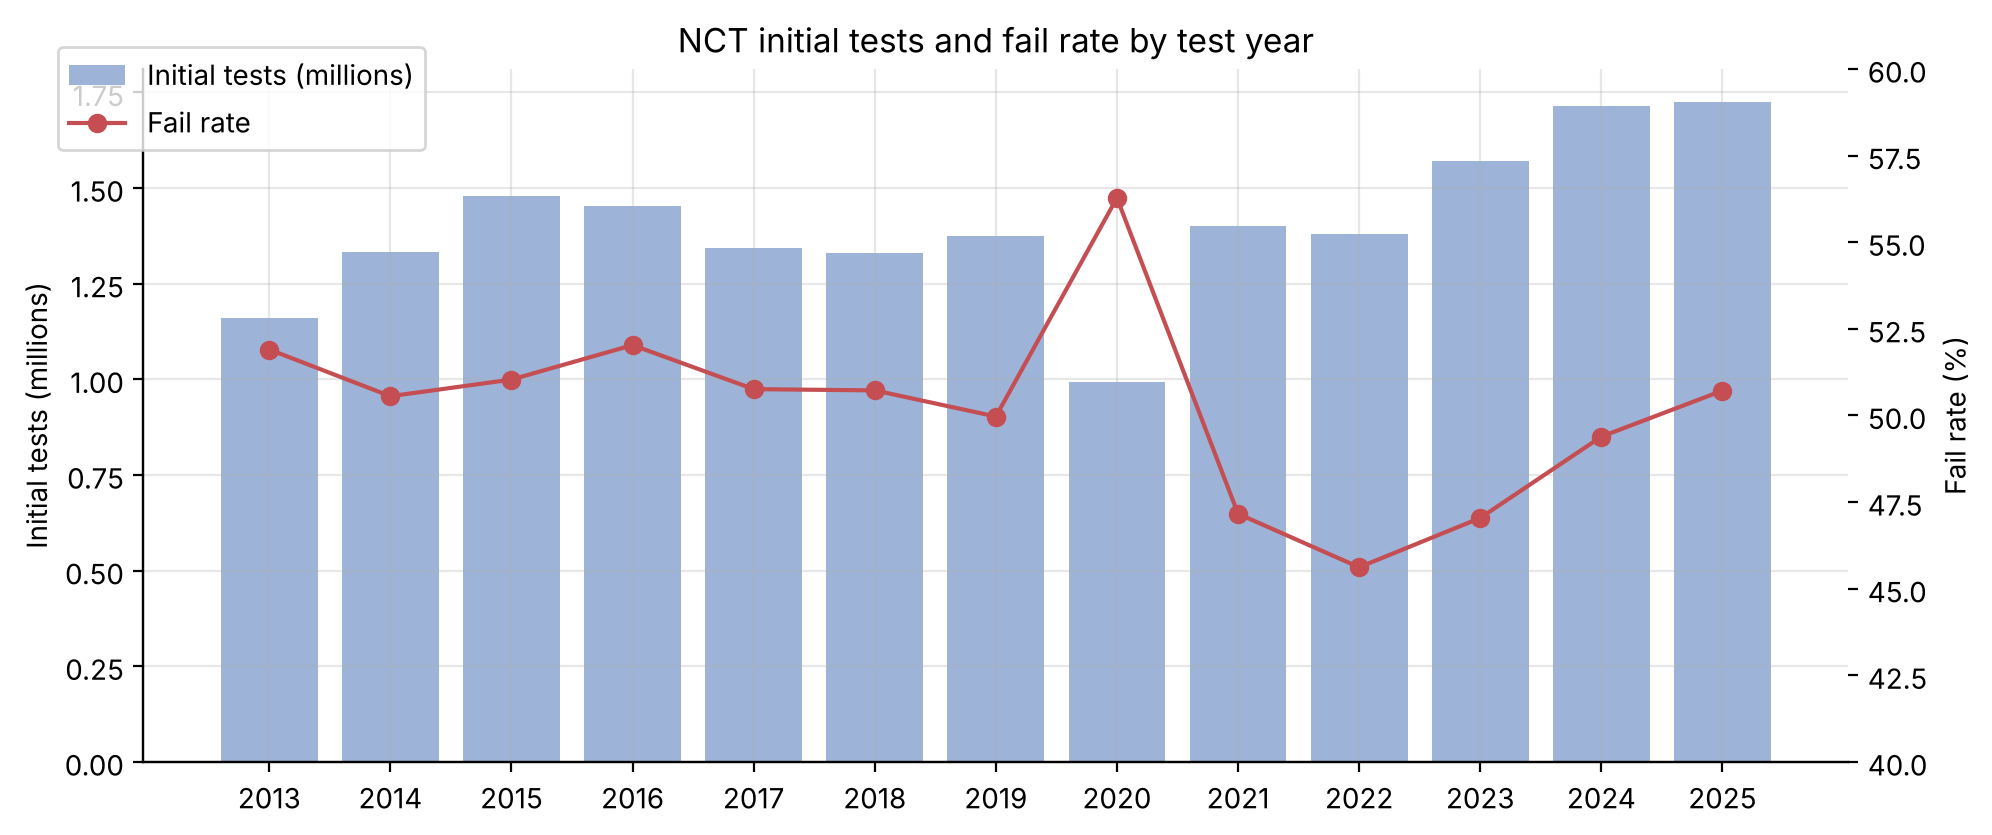

,tests,fail_rate,average_age
test_year,,,
2013,"1,160,547",51.9%,10.0
2014,"1,333,151",50.6%,10.1
2015,"1,480,354",51.0%,10.5
2016,"1,453,120",52.0%,10.7
2017,"1,342,352",50.8%,10.9
2018,"1,329,832",50.7%,10.8
2019,"1,375,647",50.0%,10.7
2020,"992,414",56.3%,10.3
2021,"1,401,761",47.2%,10.7


In [12]:
def fail_rate(table):
    """Overall fail rate of a table of groups (weighted by cars tested)."""
    return table["fail"].sum() / table["total"].sum()


nct = nct_raw[nct_raw["total"] >= MIN_GROUP].copy()
nct["age"] = nct["test_year"] - nct["year_of_birth"]

yearly = nct.groupby("test_year").apply(lambda d: pd.Series({
    "tests": d["total"].sum(), "fail_rate": fail_rate(d),
    "average_age": np.average(d["age"], weights=d["total"])}))

fig, ax1 = plt.subplots()
ax1.bar(yearly.index, yearly["tests"] / 1e6, color="#9DB4D8", label="Initial tests (millions)")
ax1.set_ylabel("Initial tests (millions)")
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["fail_rate"] * 100, color="#C44E52", marker="o", label="Fail rate")
ax2.set_ylim(40, 60)
ax2.set_ylabel("Fail rate (%)")
ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
ax1.set_title("NCT initial tests and fail rate by test year")
ax1.set_xticks(yearly.index)
plt.show()
yearly.style.format({"tests": "{:,.0f}", "fail_rate": "{:.1%}", "average_age": "{:.1f}"})

**Observation.** About half of all cars fail their first test, a rate that stayed close to 50% between 2013 and 2019. **2020 stands out**: far fewer tests and a much higher fail rate, which coincides with the COVID-19 disruption to NCT services. 2021–2022 then had the lowest fail rates in the data before returning to about 50%. Meanwhile the average age of tested cars rose by almost two years, as Irish drivers keep their cars longer.

These year-to-year shifts affect every car, so they can't be predicted from a car's make or model. They are a source of error that any model will have when forecasting a new year.

### 4.2 Fail rate by age

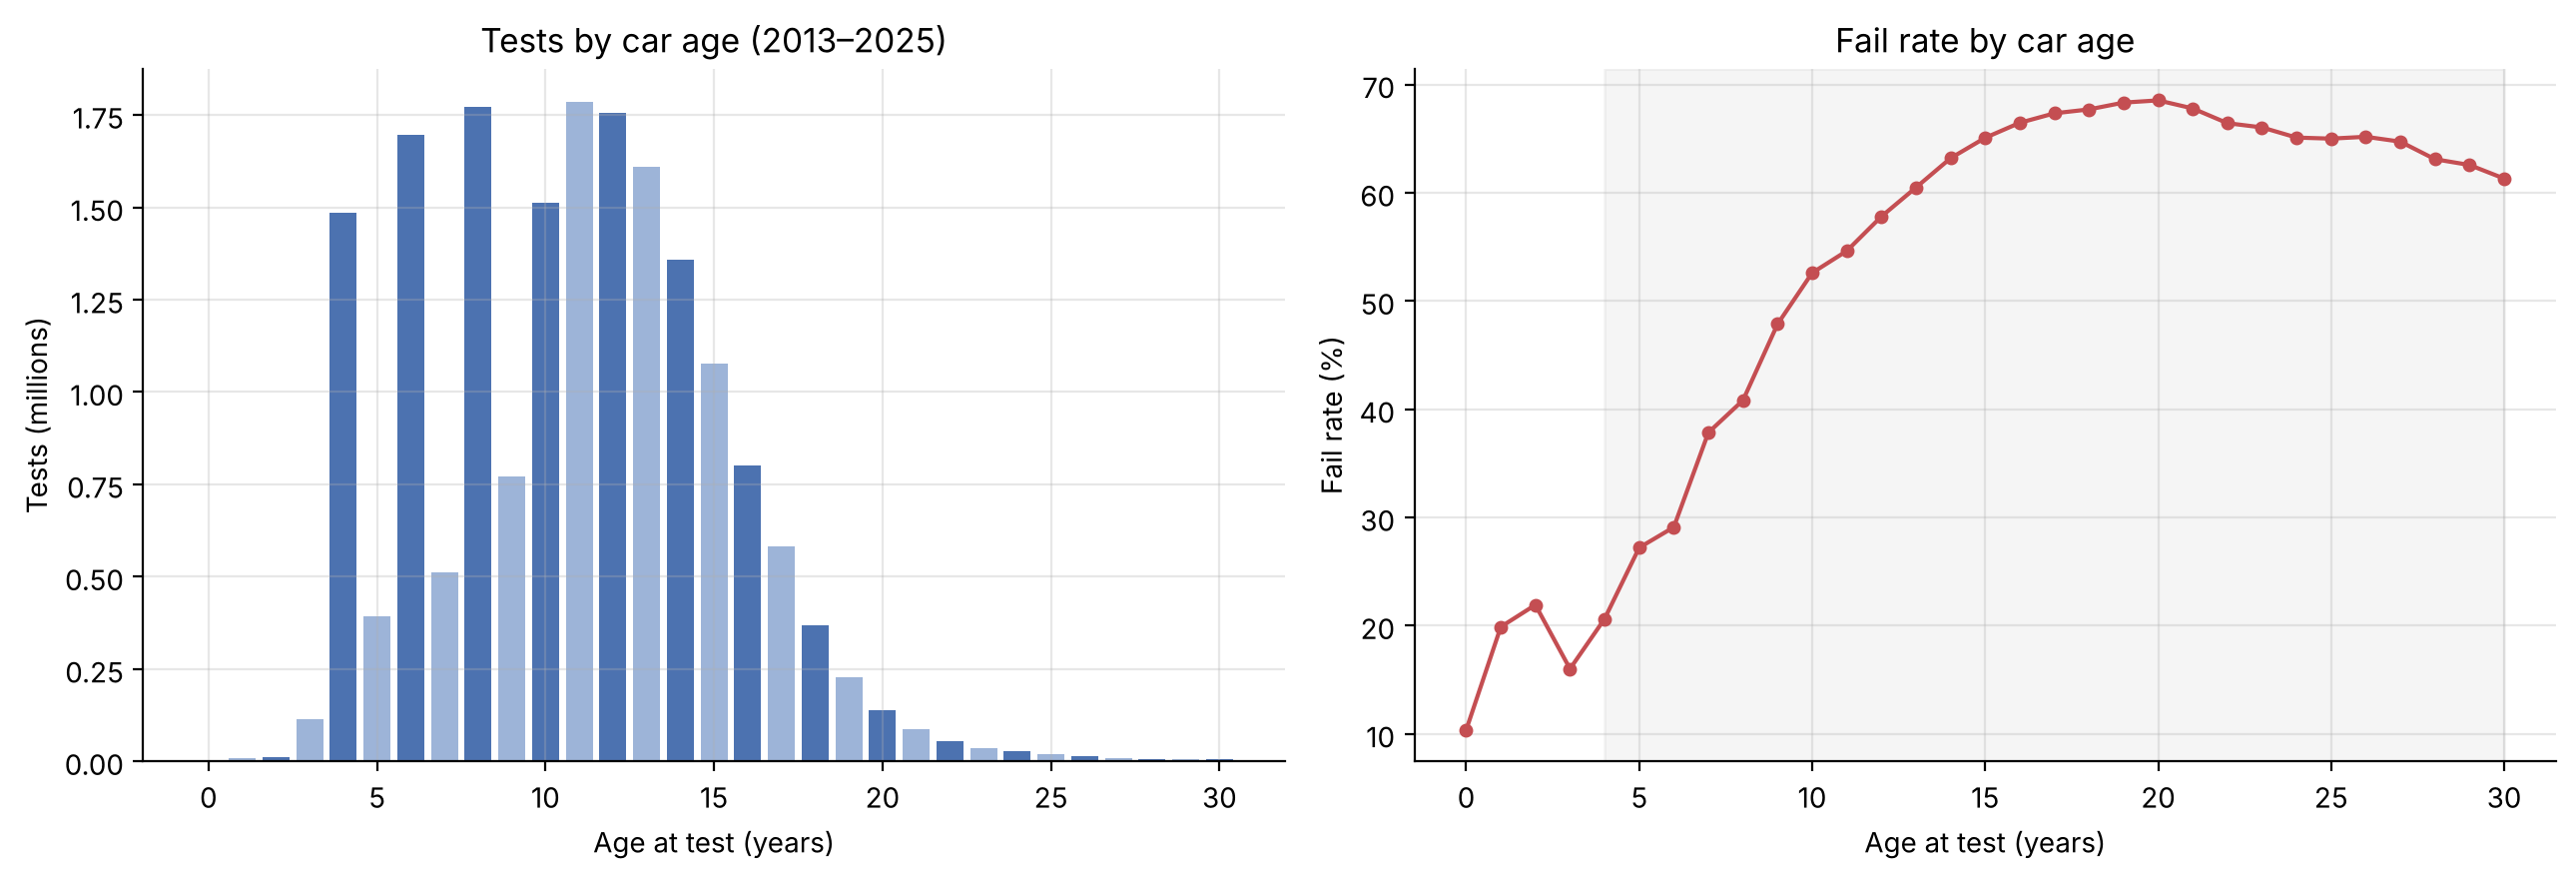

age
4     21%
6     29%
8     41%
10    53%
12    58%
15    65%
18    68%
20    69%
25    65%
30    61%


In [13]:
by_age = nct.groupby("age").agg(tests=("total", "sum"), fails=("fail", "sum"))
by_age["fail_rate"] = by_age["fails"] / by_age["tests"]
by_age = by_age.loc[0:30]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(by_age.index, by_age["tests"] / 1e6, color=np.where(by_age.index % 2 == 0, "#4C72B0", "#9DB4D8"))
ax1.set_title("Tests by car age (2013–2025)")
ax1.set_xlabel("Age at test (years)")
ax1.set_ylabel("Tests (millions)")
ax2.plot(by_age.index, by_age["fail_rate"] * 100, color="#C44E52", marker="o", markersize=4)
ax2.axvspan(*AGE_RANGE, color="grey", alpha=0.08)
ax2.set_title("Fail rate by car age")
ax2.set_xlabel("Age at test (years)")
ax2.set_ylabel("Fail rate (%)")
plt.tight_layout()
plt.show()
print(by_age.loc[[4, 6, 8, 10, 12, 15, 18, 20, 25, 30], "fail_rate"].map("{:.0%}".format).to_string())

**Observation.** Age is by far the strongest pattern. Fail rates rise from about 21% for four-year-old cars to about two-thirds for cars aged 15–20.

- **Even ages dominate the test counts.** This is the NCT schedule: cars are tested every two years from age 4 to 10, then every year. Odd-aged cars up to 10 are mostly cars whose test date moved, for example imports.
- **Very old cars fail slightly *less*** than 18–20-year-old ones. The few cars still on the road at 25+ tend to be well looked after (some are classics), so they're not typical of their make. This is **survivor bias**, and it's why the models use ages 4–30 and group everything above 25 together.

### 4.3 Raw fail rate by make

In [14]:
recent = nct[nct["test_year"] >= 2021]
make_summary = recent.groupby("make").apply(lambda d: pd.Series({
    "tests": d["total"].sum(), "fail_rate": fail_rate(d),
    "average_age": np.average(d["age"], weights=d["total"])}))
top_makes = make_summary.sort_values("tests", ascending=False).head(15)
top_makes.sort_values("fail_rate").style.format({"tests": "{:,.0f}", "fail_rate": "{:.1%}", "average_age": "{:.1f}"})

,tests,fail_rate,average_age
make,,,
SKODA,"342,481",40.9%,9.8
HYUNDAI,"422,142",43.8%,9.3
AUDI,"453,704",44.3%,10.8
BMW,"395,161",44.4%,10.9
MERCEDES BENZ,"283,510",44.8%,11.2
KIA,"240,438",45.3%,9.4
SEAT,"132,836",45.8%,10.2
TOYOTA,"1,072,520",47.6%,13.1
HONDA,"192,756",48.1%,12.8


**Observation.** Raw fail rates differ a lot between makes, but so does the average age of their cars. A make whose cars are mostly old will look worse even if it's well built, so the raw ranking is **confounded by age**. A fair comparison has to compare cars of the same age. Section 9 does this.

### 4.4 What cars fail on

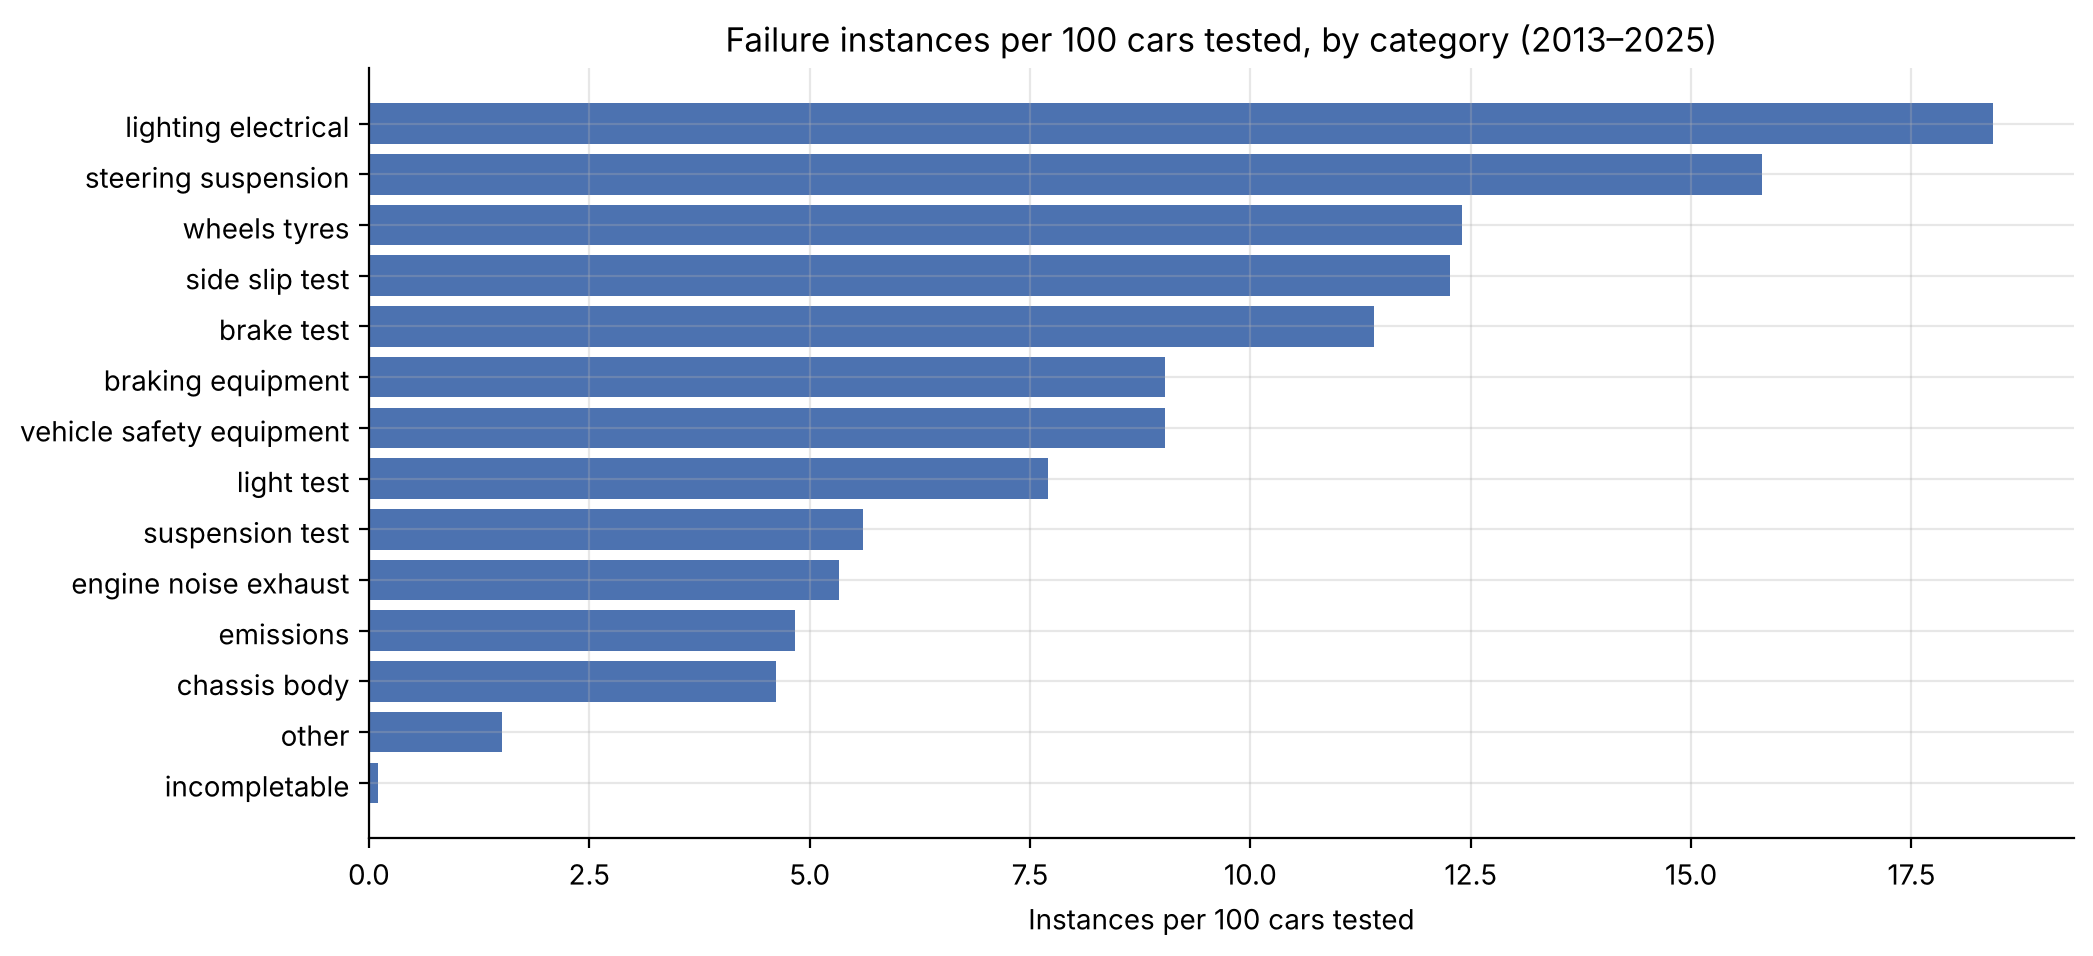

In [15]:
category_rates = pd.Series({c: nct[c].sum() / nct["total"].sum() for c in CATEGORIES}).sort_values()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh([c.replace("_", " ") for c in category_rates.index], category_rates.values * 100, color="#4C72B0")
ax.set_title("Failure instances per 100 cars tested, by category (2013–2025)")
ax.set_xlabel("Instances per 100 cars tested")
plt.show()

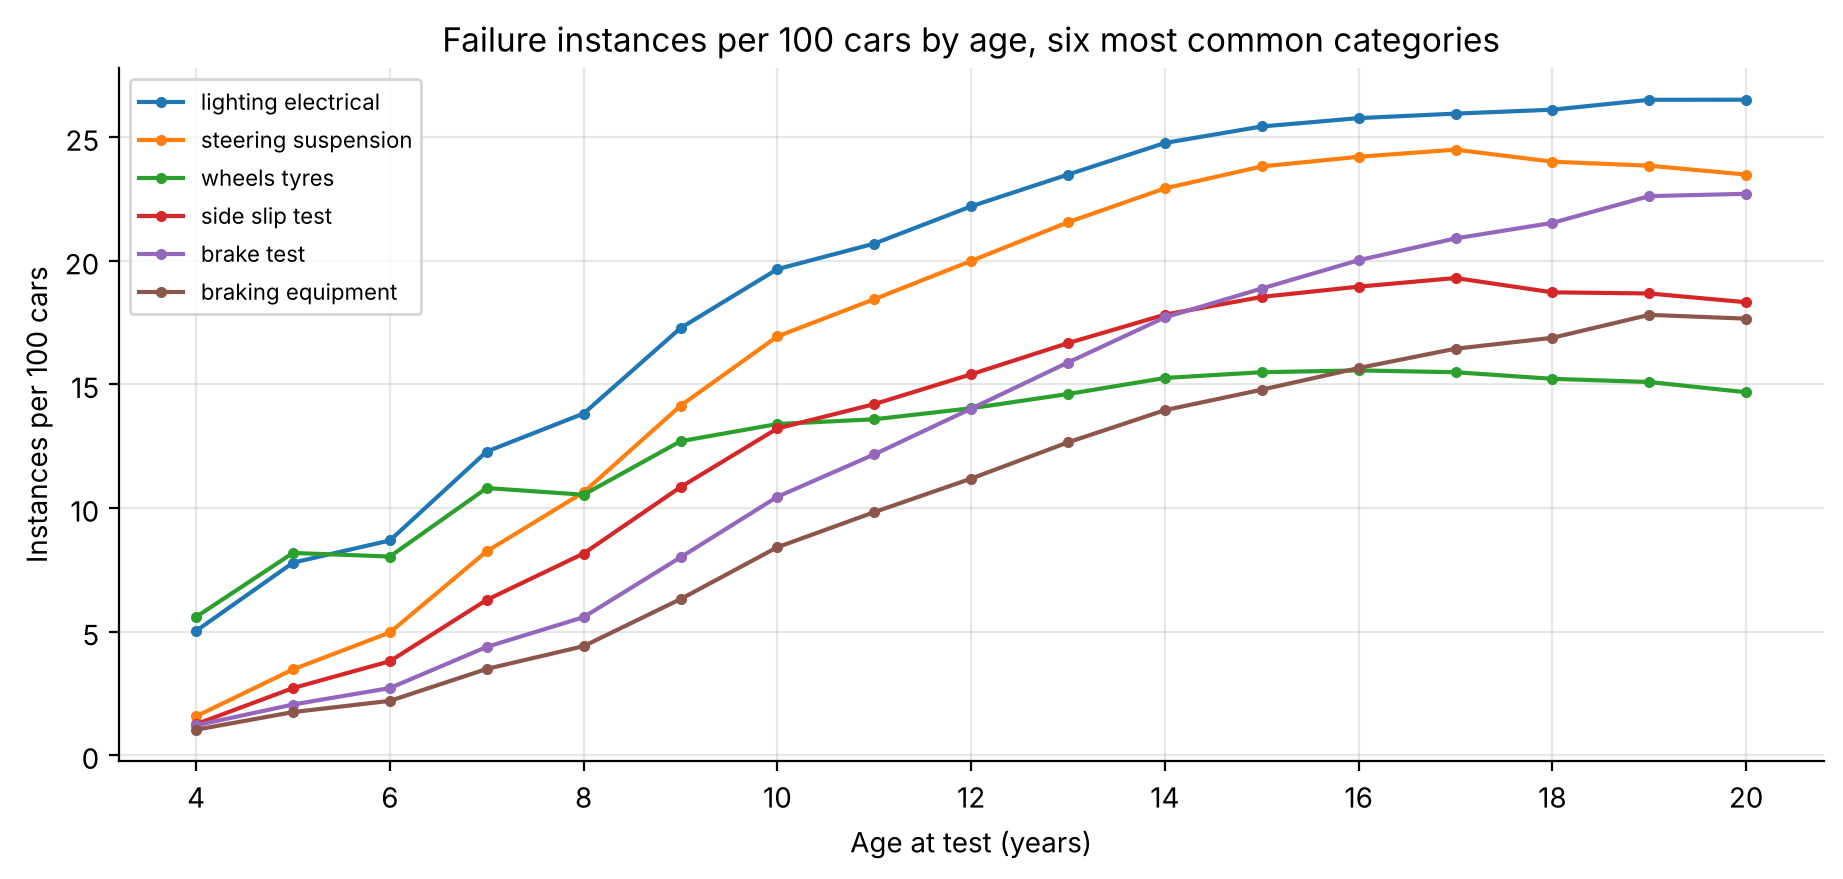

In [16]:
MAIN_CATEGORIES = category_rates.sort_values(ascending=False).index[:6]
category_by_age = nct[nct["age"].between(4, 20)].groupby("age").apply(
    lambda d: pd.Series({c: d[c].sum() / d["total"].sum() * 100 for c in MAIN_CATEGORIES}))

fig, ax = plt.subplots()
category_by_age.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Failure instances per 100 cars by age, six most common categories")
ax.set_xlabel("Age at test (years)")
ax.set_ylabel("Instances per 100 cars")
ax.legend([c.replace("_", " ") for c in MAIN_CATEGORIES], fontsize=8)
plt.show()

**Observation.** **Steering and suspension** and **lighting and electrical** faults are the most common reasons for failing, followed by the other categories shown above. Almost every category becomes more common with age, but at different speeds: wear-and-tear items such as suspension and brakes rise steeply. These differences are what Section 10 uses to group models by their failure profile.

### 4.5 Newer cars at the same age

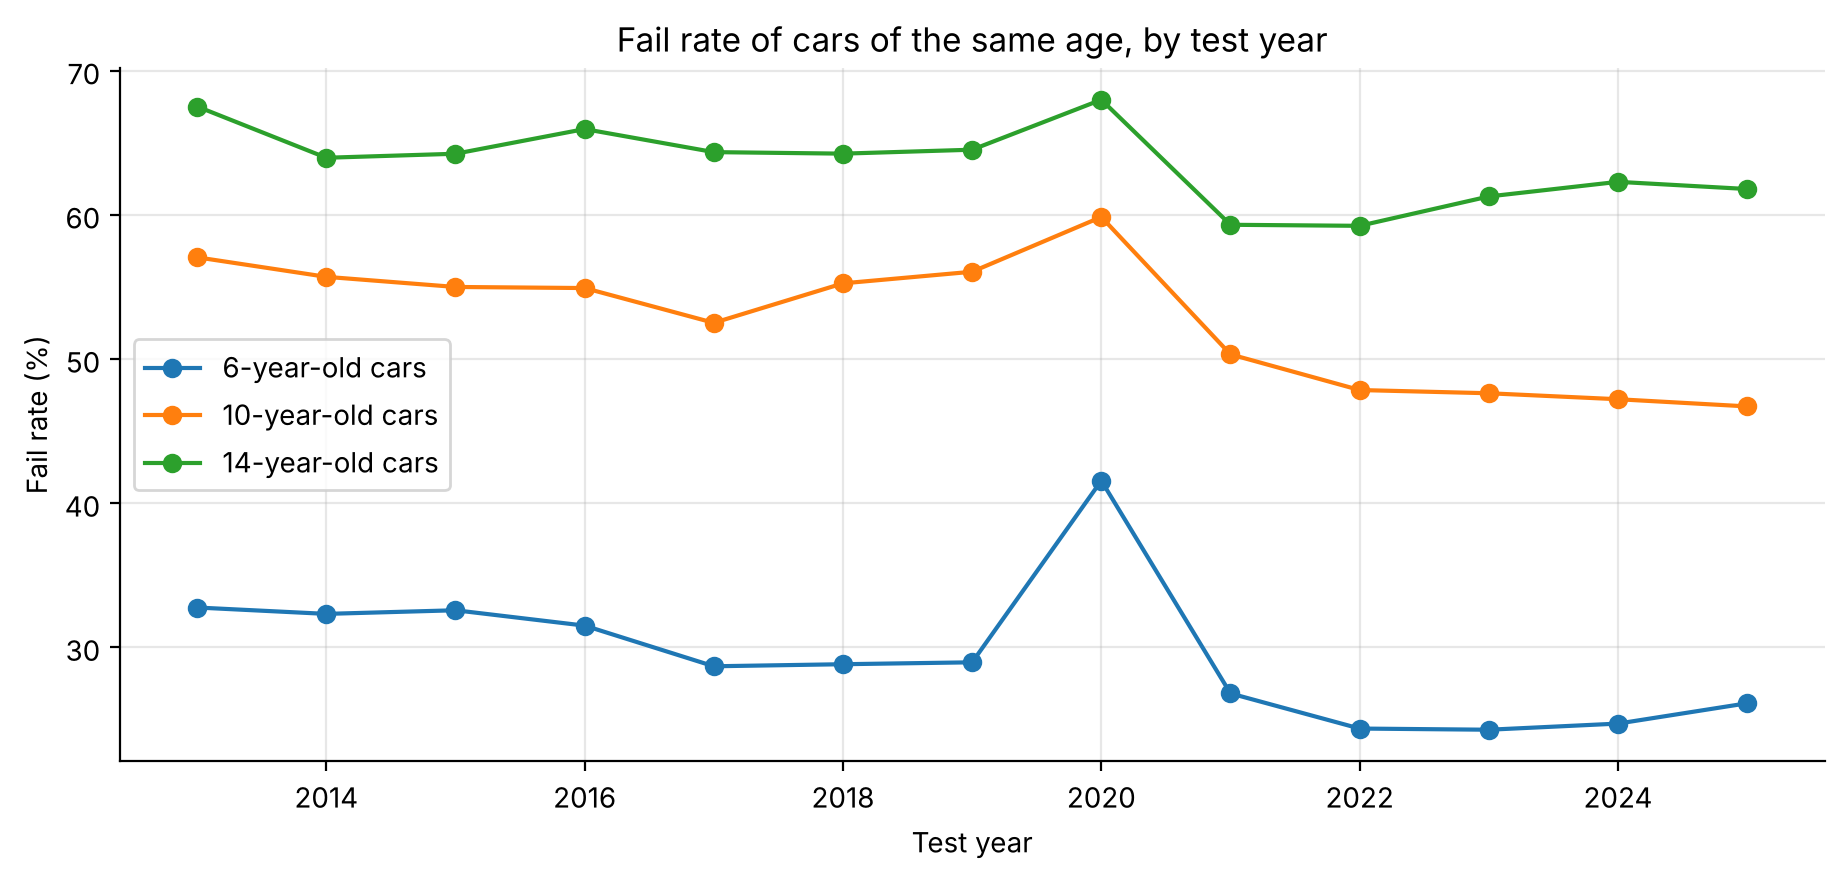

In [17]:
same_age = nct[nct["age"].isin([6, 10, 14])].groupby(["age", "test_year"]).apply(fail_rate).unstack(0)

fig, ax = plt.subplots()
(same_age * 100).plot(ax=ax, marker="o")
ax.set_title("Fail rate of cars of the same age, by test year")
ax.set_xlabel("Test year")
ax.set_ylabel("Fail rate (%)")
ax.legend([f"{a}-year-old cars" for a in same_age.columns])
plt.show()

**Observation.** Comparing cars of the *same* age across test years separates the effect of age from the effect of when the car was built. Apart from the 2020 spike, the fail rate for cars of the same age has generally fallen over time: for 10-year-old cars, from about 57% in 2013 to about 47% in 2025. More recently built cars seem to hold up better at the same age, so a car's **year of birth** carries information beyond its age, which the models in Section 8 use. One caution: much of the fall happened in a single step after 2020, so part of it may reflect changes in testing rather than build quality alone.

## 5. Data quality summary

In [18]:
def nct_quality_report(raw):
    """Summarise the data quality issues found while loading and exploring the data."""
    n_rows, n_tests = len(raw), raw["total"].sum()
    small = raw["total"] < MIN_GROUP
    age = raw["test_year"] - raw["year_of_birth"]
    out_of_range = ~age.between(*AGE_RANGE)
    other_model = raw["model"].eq("OTHER")
    issues = [
        ("Consistency", "Privacy suppression changed: groups of 1+ cars (2013–20), 6+ (2021–24), 11+ (2025)",
         small.sum(), raw.loc[small, "total"].sum(), f"Fixed: groups under {MIN_GROUP} cars removed in every year"),
        ("Validity", f"Car age outside {AGE_RANGE[0]}–{AGE_RANGE[1]} (imports, very old cars)",
         out_of_range.sum(), raw.loc[out_of_range, "total"].sum(), "Excluded from modelling (Section 7)"),
        ("Relevance", "Model recorded only as 'OTHER'", other_model.sum(), raw.loc[other_model, "total"].sum(),
         "Kept: treated as its own group per make"),
        ("Timeliness", "2020: COVID-19 disruption (fewer tests, higher fail rate)",
         (raw["test_year"] == 2020).sum(), raw.loc[raw["test_year"] == 2020, "total"].sum(),
         "Kept, but noted as an unusual year"),
        ("Consistency", "Detailed engine variants as separate models in early years",
         "–", "–", "Mostly removed by the minimum group size"),
        ("Accuracy", "PDF years must be rebuilt from text (3 files)",
         int(raw["test_year"].isin([2013, 2014, 2016]).sum()),
         raw.loc[raw["test_year"].isin([2013, 2014, 2016]), "total"].sum(), "Verified: all checks in Section 3.5 pass"),
        ("Completeness", "No mileage, maintenance or service history", "–", "–",
         "Can't be fixed: stated as a limitation"),
    ]
    report = pd.DataFrame(issues, columns=["dimension", "issue", "rows", "tests", "action"])
    report["% of tests"] = [t / n_tests if isinstance(t, (int, float, np.integer, np.floating)) else np.nan
                            for t in report["tests"]]
    for column in ["rows", "tests"]:
        report[column] = [f"{v:,.0f}" if isinstance(v, (int, float, np.integer, np.floating)) else v
                          for v in report[column]]
    return report


nct_quality_report(nct_raw).style.format({"% of tests": "{:.1%}"}, na_rep="–")

,dimension,issue,rows,tests,action,% of tests
0,Consistency,"Privacy suppression changed: groups of 1+ cars (2013–20), 6+ (2021–24), 11+ (2025)","38,040","132,564",Fixed: groups under 11 cars removed in every year,0.7%
1,Validity,"Car age outside 4–30 (imports, very old cars)","8,631","169,018",Excluded from modelling (Section 7),0.9%
2,Relevance,Model recorded only as 'OTHER',"10,168","536,596",Kept: treated as its own group per make,2.9%
3,Timeliness,"2020: COVID-19 disruption (fewer tests, higher fail rate)","8,651","1,006,983","Kept, but noted as an unusual year",5.5%
4,Consistency,Detailed engine variants as separate models in early years,–,–,Mostly removed by the minimum group size,–
5,Accuracy,PDF years must be rebuilt from text (3 files),"22,305","3,980,852",Verified: all checks in Section 3.5 pass,21.6%
6,Completeness,"No mileage, maintenance or service history",–,–,Can't be fixed: stated as a limitation,–


**Observation.** The biggest consistency problem is the change in privacy rules: before 2021 the RSA published groups as small as one car, while 2025 hides any group under 11. Comparing years fairly needs the same rule everywhere, so groups under 11 cars are removed from every year. That removes about half of the *rows* in early years, but under 1% of the *tests*, because those groups are tiny. All other issues affect a small share of tests or are handled in the preparation steps.

## 6. Provenance, licence and ethics

**Provenance.** All files are published by the **Road Safety Authority (RSA)**, which oversees the National Car Testing Service, through its website (rsa.ie, *NCT statistics and annual reviews*) and Ireland's open data portal (data.gov.ie, *Make Model Year Failures at NCT*). One file per test year, 2013–2025, plus the 2025 results by test centre used for the cross-check in Section 3.5. The figures relate to **initial tests only**: retests aren't included.

**Licence.** The data is published by a public body as open data. Datasets on data.gov.ie are normally released under the Creative Commons Attribution 4.0 licence, which allows reuse with credit, and the RSA is credited in the References.

**Ethics.**

- **Privacy.** The data contains no personal information. The RSA removes small make/model/year groups because they could indirectly identify individual owners (for GDPR reasons), and this project goes further by applying the strictest rule (11+ cars) to every year.
- **Fairness to manufacturers.** The RSA states that the figures don't account for mileage, maintenance or service history, and that it doesn't interpret them. An NCT fail is not the same as an unreliable car: a make whose cars do high mileage, or are owned by people who spend less on maintenance, will fail more often for reasons that aren't the manufacturer's fault. Results are therefore described as *NCT fail rates*, not as reliability ratings.
- **Use.** Predictions are averages for a type of car. They say nothing certain about any individual car, which may be in much better or worse condition.

## 7. Data preparation

Three steps prepare the data for modelling:

1. **Group size and age filters:** keep groups of at least `MIN_GROUP` cars aged 4–30.
2. **Features:** `age` (capped at 25), `make`, `make_model` (make and model together, so that, for example, *FORD FOCUS* and a different make's *FOCUS* can never be confused) and `year_of_birth`.
3. **From groups to cars.** The models in Section 8 predict pass or fail for individual cars. Each group row is turned into **two weighted rows**: one labelled *fail* with weight = number of cars that failed, and one labelled *pass* with weight = number that passed. This is exactly equivalent to having one row per car, but with 2 rows per group instead of up to 9,000.

In [19]:
model_data = nct[nct["age"].between(*AGE_RANGE)].copy()
model_data["age_capped"] = model_data["age"].clip(upper=AGE_CAP)
model_data["make_model"] = model_data["make"] + " | " + model_data["model"]


def to_car_level(groups):
    """Two weighted rows per group: label 1 weighted by fails, label 0 weighted by passes."""
    failed = groups.assign(failed=1, weight=groups["fail"])
    passed = groups.assign(failed=0, weight=groups["pass"])
    return pd.concat([failed, passed], ignore_index=True)


print(f"{len(model_data):,} groups, {model_data['total'].sum():,.0f} tests "
      f"({model_data['total'].sum() / nct_raw['total'].sum():.1%} of all initial tests)")
print(f"{model_data['make'].nunique()} makes, {model_data['make_model'].nunique()} make/model combinations")

52,521 groups, 18,105,437 tests (98.5% of all initial tests)
60 makes, 863 make/model combinations


## 8. Modelling: predicting fail rates

### 8.1 Train, validation and test years

As in Projects 1 and 2, the split is **by time**, so the models are always predicting a year they haven't seen:

| Set | Test years | Used for |
|---|---|---|
| Training | 2013–2023 | Fitting the models |
| Validation | 2024 | Choosing features and settings |
| Test | 2025 | Final evaluation, used once |

For the final test, each chosen model is refitted on 2013–2024 and then scored on 2025.

In [20]:
train = model_data[model_data["test_year"] <= TRAIN_LAST]
valid = model_data[model_data["test_year"] == VALID_YEAR]
train_full = model_data[model_data["test_year"] <= VALID_YEAR]
test = model_data[model_data["test_year"] == TEST_YEAR]
for name, part in [("Training", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:11s} {part['test_year'].min()}–{part['test_year'].max()}: "
          f"{len(part):,} groups, {part['total'].sum():,.0f} tests")

Training    2013–2023: 42,561 groups, 14,688,696 tests
Validation  2024–2024: 4,932 groups, 1,703,335 tests
Test        2025–2025: 5,028 groups, 1,713,406 tests


### 8.2 How predictions are scored

In [21]:
def score(groups, predicted):
    """Group error (percentage points, weighted by cars) plus car-level probability scores."""
    actual = groups["fail"] / groups["total"]
    cars = to_car_level(groups.assign(predicted=predicted))
    return {
        "group error (pp)": 100 * np.average(np.abs(predicted - actual), weights=groups["total"]),
        "log loss": log_loss(cars["failed"], cars["predicted"], sample_weight=cars["weight"]),
        "Brier score": brier_score_loss(cars["failed"], cars["predicted"], sample_weight=cars["weight"]),
        "ROC AUC": roc_auc_score(cars["failed"], cars["predicted"], sample_weight=cars["weight"]),
    }


def results_table(results):
    return pd.DataFrame(results).T.style.format(
        {"group error (pp)": "{:.2f}", "log loss": "{:.4f}", "Brier score": "{:.4f}", "ROC AUC": "{:.3f}"})

**Group error** is the easiest to interpret: if a model predicts 40% for 2015 Ford Focuses and 43% actually failed, the error is 3 percentage points. It's weighted by the number of cars, so common cars count for more. **Log loss**, **Brier score** and **ROC AUC** treat each tested car as one prediction, as in Project 2. The AUC can never get close to 1 here, because cars of the same make, model and age get the same prediction, and many of them pass while others fail.

### 8.3 Baselines: look-up tables

The simplest predictions come straight from the training data: the average fail rate overall, for cars of the same age, for the same make and age, or for the same model and age. Small groups give noisy averages, so the look-ups are **smoothed**: a group's rate is pulled towards the next simpler average, as if `PRIOR_STRENGTH` extra cars had been added at that average.

$$\text{smoothed rate} = \frac{\text{fails} + m \times \text{prior rate}}{\text{tests} + m}$$

In [22]:
def lookup(train_groups, keys, target_groups, prior):
    """Smoothed fail rate per key from the training data; unseen keys get the prior."""
    stats = train_groups.groupby(keys).agg(fails=("fail", "sum"), tests=("total", "sum"))
    joined = target_groups[keys].merge(stats, left_on=keys, right_index=True, how="left")
    return ((joined["fails"].fillna(0) + PRIOR_STRENGTH * prior)
            / (joined["tests"].fillna(0) + PRIOR_STRENGTH)).to_numpy()


def baseline_predictions(train_groups, target_groups):
    overall = np.full(len(target_groups), fail_rate(train_groups))
    by_age = lookup(train_groups, ["age_capped"], target_groups, overall)
    return {
        "Baseline: overall rate": overall,
        "Baseline: same age": by_age,
        "Baseline: same make and age": lookup(train_groups, ["make", "age_capped"], target_groups, by_age),
        "Baseline: same model and age": lookup(train_groups, ["make_model", "age_capped"], target_groups, by_age),
    }


validation_results = {name: score(valid, p) for name, p in baseline_predictions(train, valid).items()}
results_table(validation_results)

,group error (pp),log loss,Brier score,ROC AUC
Baseline: overall rate,15.02,0.6932,0.2500,0.500
Baseline: same age,6.99,0.6451,0.2268,0.677
Baseline: same make and age,6.25,0.6414,0.2251,0.683
Baseline: same model and age,5.21,0.6374,0.2233,0.688


**Observation.** Knowing the car's age alone more than halves the error compared with the overall average. Adding the make, and then the specific model, improves the predictions further. The model-and-age look-up is a strong baseline: it predicts 2024 fail rates to within about 5 percentage points on average.

### 8.4 Logistic regression

Logistic regression predicts the probability that a car fails. The inputs are turned into 0/1 (one-hot) columns: one per age, one per make and one per make/model. Further features are added one at a time and tested on 2024:

- **Brand ageing:** a separate age slope for each make, so a brand whose cars deteriorate faster gets a steeper curve. These are make × age *interaction* columns.
- **Model ageing:** the same for each model.
- **Year of birth** (in 3-year bands): newer cars of the same age fail less (Section 4.5).
- **Recency weighting:** recent test years count more, because fail rates shift from year to year (Section 4.1). A test year that is *h* years older than the newest counts half as much (`half_life` = *h*).

`C` controls the regularisation strength, as in Project 2.

In [23]:
def logistic_features(groups, encoders=None, brand_ageing=False, model_ageing=False, cohort=False):
    """One-hot features plus optional age-slope interactions. Fits the encoders the first time."""
    groups = groups.assign(yob_band=(groups["year_of_birth"] // 3 * 3).clip(lower=1995))
    categorical = ["age_capped", "make", "make_model"] + (["yob_band"] if cohort else [])
    slopes = (["make"] if brand_ageing else []) + (["make_model"] if model_ageing else [])
    if encoders is None:
        encoders = {"main": OneHotEncoder(handle_unknown="ignore").fit(groups[categorical].astype(str))}
        for key in slopes:
            encoders[key] = OneHotEncoder(handle_unknown="ignore").fit(groups[[key]])
    blocks = [encoders["main"].transform(groups[categorical].astype(str))]
    centred_age = ((groups["age_capped"] - 10) / 10).to_numpy()[:, None]
    for key in slopes:
        blocks.append(encoders[key].transform(groups[[key]]).multiply(centred_age))
    return sparse.hstack(blocks).tocsr(), encoders


def fit_logistic(train_groups, C=1.0, half_life=None, **feature_options):
    """Fit logistic regression on car-level weighted rows."""
    cars = to_car_level(train_groups)
    X, encoders = logistic_features(cars, **feature_options)
    weights = cars["weight"].to_numpy(dtype=float)
    if half_life:
        weights = weights * 0.5 ** ((cars["test_year"].max() - cars["test_year"].to_numpy()) / half_life)
    model = LogisticRegression(C=C, max_iter=5000).fit(X, cars["failed"], sample_weight=weights / weights.mean())
    return model, encoders, feature_options


def predict_logistic(fitted, groups):
    model, encoders, feature_options = fitted
    X, _ = logistic_features(groups, encoders, **feature_options)
    return model.predict_proba(X)[:, 1]

In [24]:
LOGISTIC_STEPS = {
    "LR: age + make + model": dict(),
    "LR: + brand ageing": dict(brand_ageing=True),
    "LR: + model ageing": dict(brand_ageing=True, model_ageing=True),
    "LR: + year of birth": dict(brand_ageing=True, model_ageing=True, cohort=True),
    "LR: + recency (half-life 2)": dict(brand_ageing=True, model_ageing=True, cohort=True, half_life=2),
    "LR: + recency (half-life 3)": dict(brand_ageing=True, model_ageing=True, cohort=True, half_life=3),
    "LR: + recency (half-life 5)": dict(brand_ageing=True, model_ageing=True, cohort=True, half_life=5),
}
for name, options in LOGISTIC_STEPS.items():
    validation_results[name] = score(valid, predict_logistic(fit_logistic(train, **options), valid))
results_table(validation_results)

,group error (pp),log loss,Brier score,ROC AUC
Baseline: overall rate,15.02,0.6932,0.2500,0.500
Baseline: same age,6.99,0.6451,0.2268,0.677
Baseline: same make and age,6.25,0.6414,0.2251,0.683
Baseline: same model and age,5.21,0.6374,0.2233,0.688
LR: age + make + model,5.52,0.6384,0.2237,0.689
LR: + brand ageing,5.27,0.6376,0.2234,0.690
LR: + model ageing,5.14,0.6372,0.2232,0.690
LR: + year of birth,4.18,0.6344,0.2219,0.692
LR: + recency (half-life 2),3.91,0.6336,0.2215,0.693
LR: + recency (half-life 3),3.87,0.6335,0.2215,0.693


**Observation.** On its own, the basic logistic regression (age, make and model) is slightly *worse* than the model-and-age look-up, because it assumes every model ages in the same way. Each added feature then helps on 2024:

- Brand and model ageing give modest gains, enough to beat the look-up.
- **Year of birth gives the largest single improvement**, confirming Section 4.5: newer cars hold up better at the same age.
- Recency weighting then helps further, because the fail-rate level drifts from year to year and recent years are a better guide.

The best setting on 2024 is chosen automatically below and refitted on 2013–2024 for the final test.

In [25]:
logistic_names = [n for n in validation_results if n.startswith("LR")]
BEST_LOGISTIC = min(logistic_names, key=lambda n: validation_results[n]["group error (pp)"])
print("Chosen logistic regression:", BEST_LOGISTIC, LOGISTIC_STEPS[BEST_LOGISTIC])

Chosen logistic regression: LR: + recency (half-life 3) {'brand_ageing': True, 'model_ageing': True, 'cohort': True, 'half_life': 3}


### 8.5 Decision tree

A **decision tree** splits the cars into groups by asking yes/no questions, such as *is the car older than 9?* or *is this model's record worse than average?*, and predicts the fail rate in each final group (leaf). Trees can't use 600 one-hot model columns well, so each make and model is summarised by a single number instead: its **age-adjusted fail ratio** in the training data (actual fails ÷ the fails expected for cars of the same ages, smoothed towards 1). This is called **target encoding**, and it's calculated from training years only.

The tree's depth and minimum leaf size are tuned on 2024.

In [26]:
def fail_ratio_encoding(train_groups, key, strength=200):
    """Age-adjusted, smoothed fail ratio per make or model (1.0 = average for its age)."""
    age_rate = train_groups.groupby("age_capped").apply(fail_rate)
    expected = train_groups["total"] * train_groups["age_capped"].map(age_rate)
    stats = train_groups.assign(expected=expected).groupby(key).agg(fails=("fail", "sum"), expected=("expected", "sum"))
    return (stats["fails"] + strength) / (stats["expected"] + strength)


def tree_features(groups, encodings):
    return pd.DataFrame({
        "age": groups["age_capped"].to_numpy(),
        "year_of_birth": groups["year_of_birth"].to_numpy(),
        "model_ratio": groups["make_model"].map(encodings["make_model"]).fillna(1.0).to_numpy(),
        "make_ratio": groups["make"].map(encodings["make"]).fillna(1.0).to_numpy(),
    })


def fit_tree(train_groups, max_depth, min_samples_leaf, half_life=None):
    encodings = {key: fail_ratio_encoding(train_groups, key) for key in ["make", "make_model"]}
    cars = to_car_level(train_groups)
    weights = cars["weight"].to_numpy(dtype=float)
    if half_life:
        weights = weights * 0.5 ** ((cars["test_year"].max() - cars["test_year"].to_numpy()) / half_life)
    tree = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=RANDOM_SEED)
    tree.fit(tree_features(cars, encodings), cars["failed"], sample_weight=weights)
    return tree, encodings


def predict_tree(fitted, groups):
    tree, encodings = fitted
    return tree.predict_proba(tree_features(groups, encodings))[:, 1]


TREE_SETTINGS = {f"Tree: depth {d}, leaf {l}" + (f", half-life {h}" if h else ""): dict(max_depth=d, min_samples_leaf=l, half_life=h)
                 for d in [4, 6, 8, 10, 12] for l in [50, 200] for h in [None, 3]}
tree_results = {name: score(valid, predict_tree(fit_tree(train, **s), valid)) for name, s in TREE_SETTINGS.items()}
BEST_TREE = min(tree_results, key=lambda n: tree_results[n]["group error (pp)"])
print("Chosen tree:", BEST_TREE)
results_table(dict(sorted(tree_results.items(), key=lambda kv: kv[1]["group error (pp)"])[:6]))

Chosen tree: Tree: depth 12, leaf 50, half-life 3


,group error (pp),log loss,Brier score,ROC AUC
"Tree: depth 12, leaf 50, half-life 3",4.28,0.6346,0.2220,0.692
"Tree: depth 10, leaf 50, half-life 3",4.29,0.6347,0.2220,0.692
"Tree: depth 12, leaf 50",4.31,0.6348,0.2221,0.692
"Tree: depth 10, leaf 50",4.33,0.6347,0.2221,0.692
"Tree: depth 8, leaf 50, half-life 3",4.50,0.6351,0.2223,0.691
"Tree: depth 8, leaf 50",4.57,0.6353,0.2223,0.690


**What the tree learned.** The top of the chosen tree, refitted on 2013–2024:

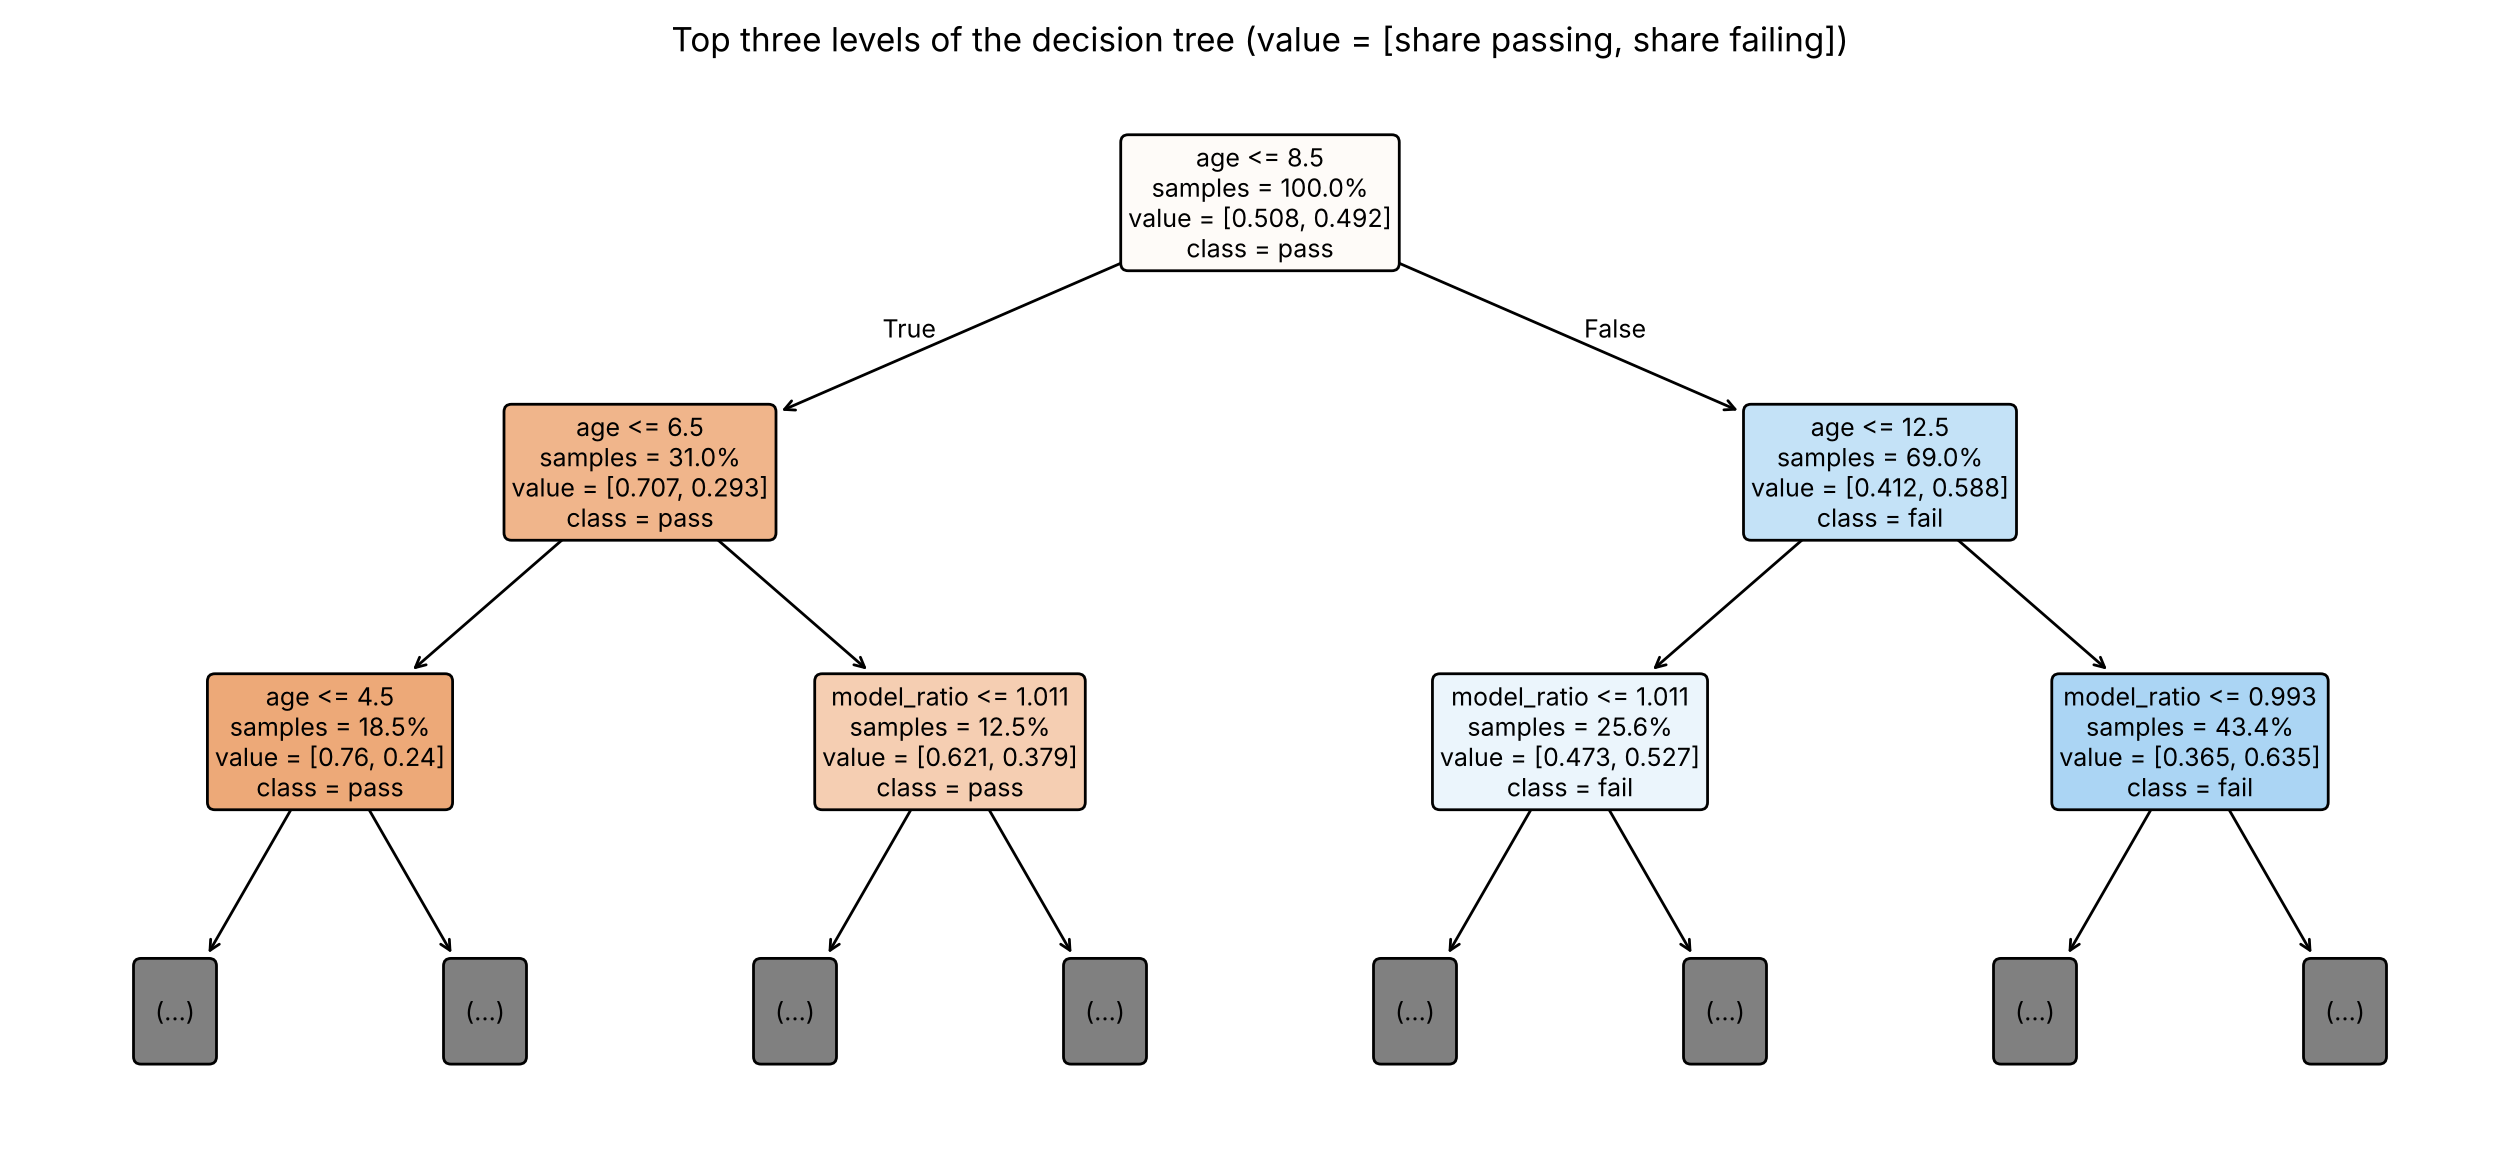

age              82%
model_ratio      12%
year_of_birth     5%
make_ratio        1%


In [27]:
final_tree = fit_tree(train_full, **TREE_SETTINGS[BEST_TREE])
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(final_tree[0], max_depth=2, feature_names=["age", "year_of_birth", "model_ratio", "make_ratio"],
          class_names=["pass", "fail"], filled=True, impurity=False, proportion=True, rounded=True,
          fontsize=9, ax=ax)
ax.set_title("Top three levels of the decision tree (value = [share passing, share failing])")
plt.show()
importance = pd.Series(final_tree[0].feature_importances_,
                       index=["age", "year_of_birth", "model_ratio", "make_ratio"]).sort_values(ascending=False)
print(importance.map("{:.0%}".format).to_string())

**Observation.** The first split is on **age**, as expected from Section 4.2, and the next levels split on the model's fail ratio and on age again. Age accounts for most of the tree's decisions, followed by the model's track record and the year of birth. The tree is easy to read, which is its main advantage over the logistic regression.

### 8.6 Final test on 2025

Each chosen model is refitted on 2013–2024 and scored once on 2025. The baselines are recalculated from 2013–2024 in the same way.

In [28]:
final_logistic = fit_logistic(train_full, **LOGISTIC_STEPS[BEST_LOGISTIC])
test_predictions = baseline_predictions(train_full, test)
test_predictions["Decision tree"] = predict_tree(final_tree, test)
test_predictions["Logistic regression"] = predict_logistic(final_logistic, test)

test_results = {name: score(test, p) for name, p in test_predictions.items()}
results_table(dict(sorted(test_results.items(), key=lambda kv: kv[1]["group error (pp)"])))

,group error (pp),log loss,Brier score,ROC AUC
Decision tree,4.08,0.6320,0.2207,0.696
Logistic regression,4.16,0.6319,0.2206,0.698
Baseline: same model and age,4.98,0.6346,0.2219,0.693
Baseline: same make and age,6.12,0.6389,0.2239,0.688
Baseline: same age,7.17,0.6435,0.2261,0.680
Baseline: overall rate,15.43,0.6931,0.2500,0.500


In [29]:
best_test = test_predictions["Logistic regression"]   # used for the tool in Section 11
actual = test["fail"] / test["total"]
print(f"Average predicted fail rate 2025: {np.average(best_test, weights=test['total']):.1%}, "
      f"actual: {fail_rate(test):.1%}")
within5 = np.average(np.abs(best_test - actual) <= 0.05, weights=test["total"])
print(f"Cars in groups predicted within 5 percentage points: {within5:.0%}")

Average predicted fail rate 2025: 48.9%, actual: 50.8%
Cars in groups predicted within 5 percentage points: 67%


**Observation.** On 2025, which no model saw during training or tuning, **both models beat every baseline**, cutting the group error of the best look-up (about 5 percentage points) to about 4. The decision tree and logistic regression are **almost tied**: the tree has a slightly smaller group error, while logistic regression has a slightly better log loss and ROC AUC, and their Brier scores are the same. The differences are too small to matter in practice. Logistic regression is used for the tool in Section 11, because its probabilities score slightly better and it uses each model's own record directly.

The models slightly **under-predict** 2025 overall (an average of 48.9% predicted against 50.8% actual). The recency weighting leans on the most recent years, which include the unusually low fail rates of 2021–2023, and 2025 moved back up. About two-thirds of cars are in groups whose fail rate was predicted to within 5 percentage points.

The remaining error is partly unavoidable. Smaller groups have noisy fail rates even if the prediction is perfect, and year-wide shifts like the 2020 spike can't be predicted from a car's make and model.

### 8.7 Predicted against actual

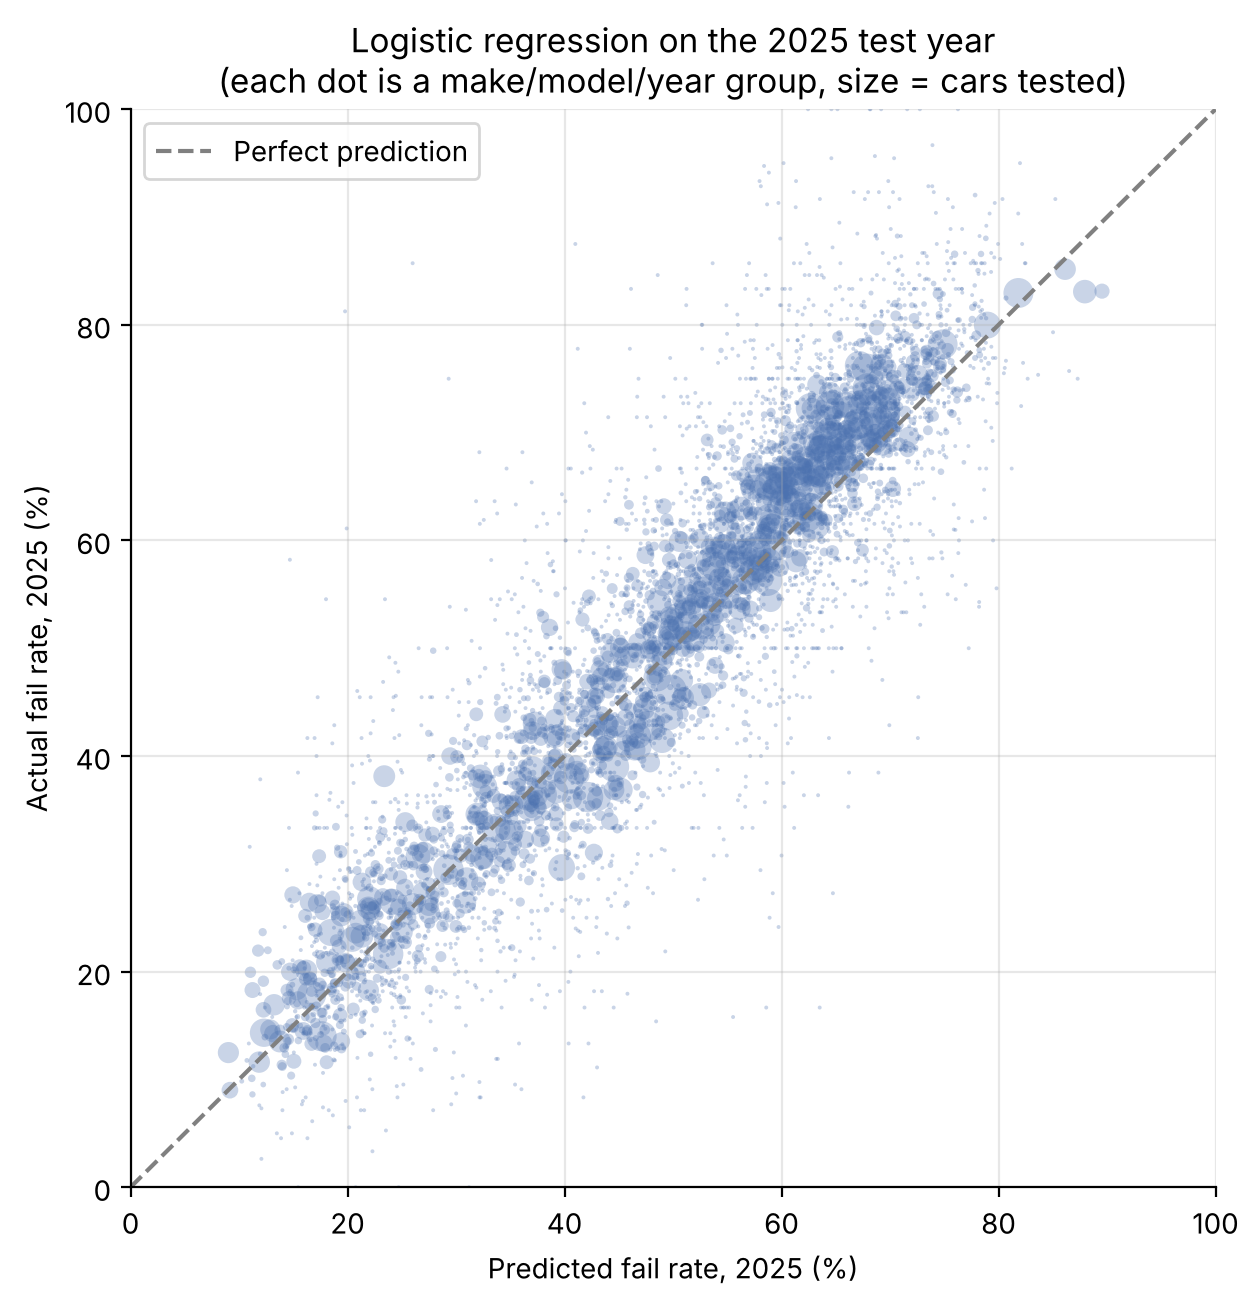

In [30]:
fig, ax = plt.subplots(figsize=(7, 7))
sizes = np.clip(test["total"] / 40, 2, 120)
ax.scatter(best_test * 100, actual * 100, s=sizes, alpha=0.3, color="#4C72B0", edgecolor="none")
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", label="Perfect prediction")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Predicted fail rate, 2025 (%)")
ax.set_ylabel("Actual fail rate, 2025 (%)")
ax.set_title("Logistic regression on the 2025 test year\n(each dot is a make/model/year group, size = cars tested)")
ax.legend()
plt.show()

**Observation.** The large dots (common cars with many tests) sit close to the diagonal. The spread is much wider for small groups, where a few cars passing or failing by chance moves the fail rate a lot. The model is most useful for the cars that most people actually own.

## 9. Which brands age best?

Section 4.3 showed that raw fail rates are confounded by age. To compare brands fairly, each make's actual number of fails is divided by the number **expected** for cars of the same age tested in the same year:

$$\text{fail ratio} = \frac{\text{actual fails}}{\text{expected fails for cars of the same ages and test years}}$$

A ratio of 0.90 means the make's cars fail 10% less often than average for their age. The ratio is calculated separately for **younger cars (4–8 years)** and **older cars (12–16 years)**. This uses the five most recent test years (2021–2025) and makes with at least 100,000 tests.

In [31]:
def fail_ratios(groups, by, min_tests=100_000):
    """Actual fails divided by the fails expected for the same ages and test years."""
    expected_rate = groups.groupby(["test_year", "age_capped"]).apply(fail_rate).rename("expected_rate")
    groups = groups.join(expected_rate, on=["test_year", "age_capped"])
    groups = groups.assign(expected=groups["total"] * groups["expected_rate"])

    def ratio(d):
        return d["fail"].sum() / d["expected"].sum()

    tests = groups.groupby(by)["total"].sum()
    keep = tests[tests >= min_tests].index
    groups = groups[groups[by].isin(keep)]
    return pd.DataFrame({
        "tests": tests[keep],
        "fail ratio (all ages)": groups.groupby(by).apply(ratio),
        "younger cars (4–8)": groups[groups["age"].between(4, 8)].groupby(by).apply(ratio),
        "older cars (12–16)": groups[groups["age"].between(12, 16)].groupby(by).apply(ratio),
    }).sort_values("fail ratio (all ages)")


recent_groups = model_data[model_data["test_year"] >= 2021]
brands = fail_ratios(recent_groups, "make")
brands.style.format({"tests": "{:,.0f}", "fail ratio (all ages)": "{:.2f}", "younger cars (4–8)": "{:.2f}",
                     "older cars (12–16)": "{:.2f}"}).background_gradient(
    subset=["fail ratio (all ages)", "younger cars (4–8)", "older cars (12–16)"], cmap="RdYlGn_r", vmin=0.7, vmax=1.3)

,tests,fail ratio (all ages),younger cars (4–8),older cars (12–16)
make,,,,
TOYOTA,"1,062,359",0.90,0.78,0.90
HONDA,"192,239",0.91,0.94,0.88
AUDI,"452,992",0.94,0.92,0.96
BMW,"393,480",0.95,0.94,0.96
SKODA,"339,459",0.95,0.90,1.00
MAZDA,"130,869",0.96,0.87,0.97
MERCEDES BENZ,"279,094",0.97,1.05,0.95
OPEL,"283,880",0.98,1.07,0.96
VOLKSWAGEN,"1,005,490",0.99,0.94,1.01


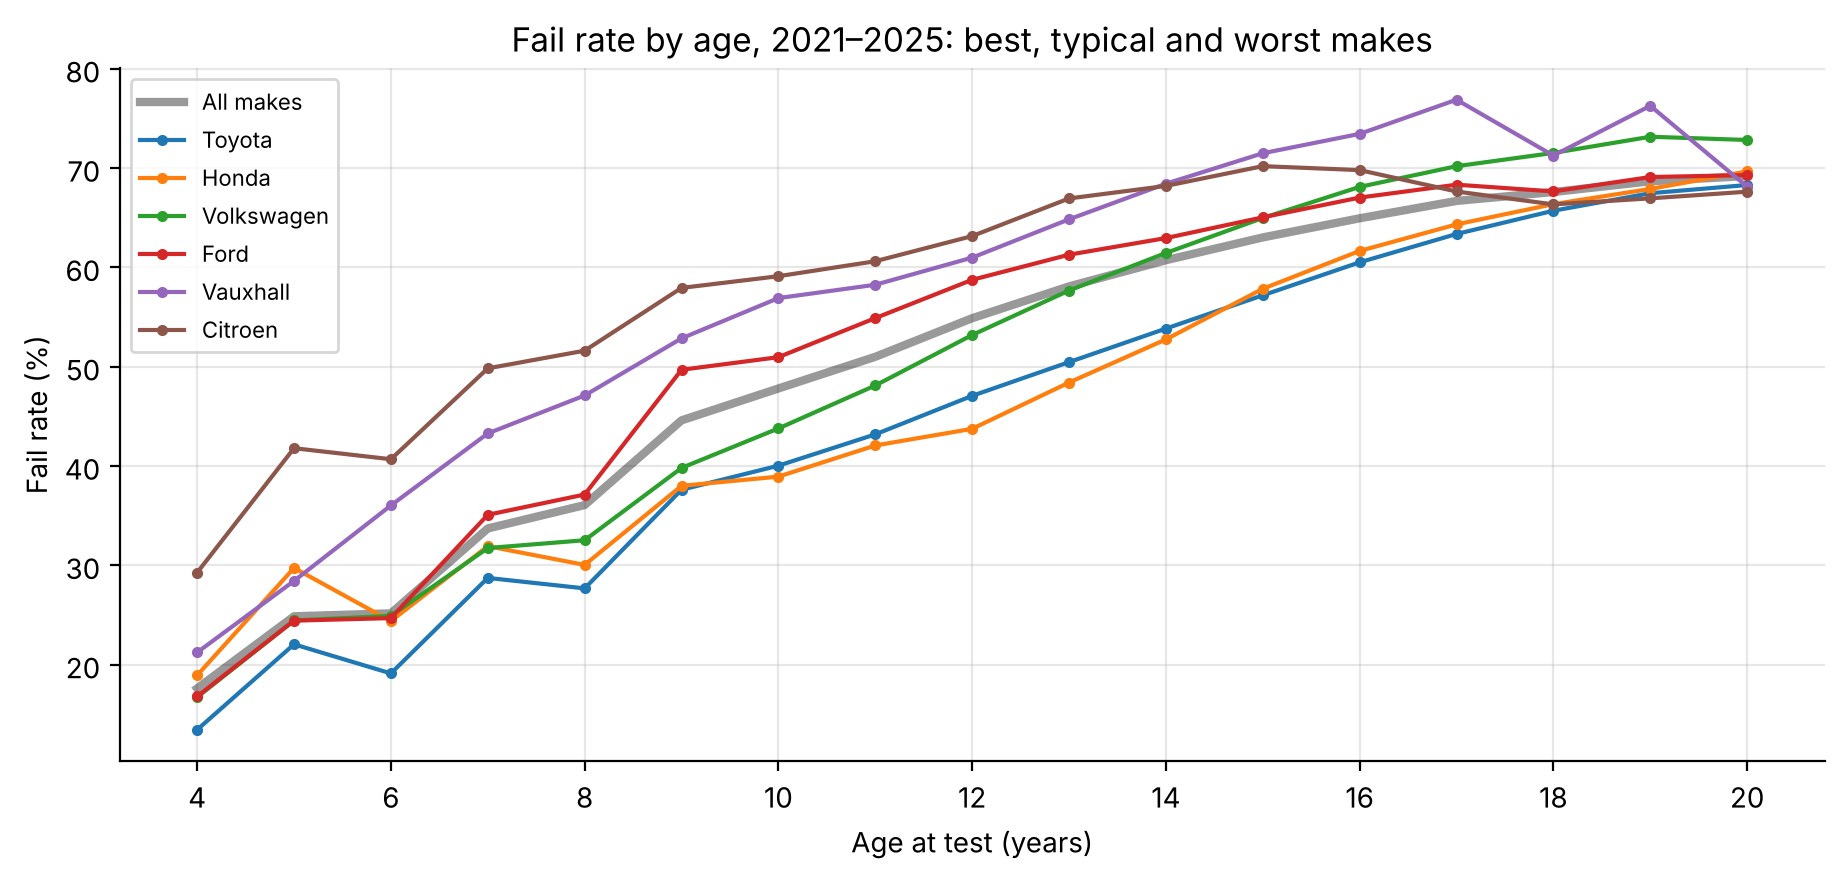

In [32]:
SHOW_MAKES = [brands.index[0], brands.index[1], "VOLKSWAGEN", "FORD", brands.index[-2], brands.index[-1]]
curves = (recent_groups[recent_groups["make"].isin(SHOW_MAKES) & recent_groups["age"].between(4, 20)]
          .groupby(["age", "make"]).apply(fail_rate).unstack())
overall_curve = recent_groups[recent_groups["age"].between(4, 20)].groupby("age").apply(fail_rate)

fig, ax = plt.subplots()
ax.plot(overall_curve.index, overall_curve * 100, color="black", linewidth=3, alpha=0.4, label="All makes")
for make in SHOW_MAKES:
    ax.plot(curves.index, curves[make] * 100, marker="o", markersize=3, label=make.title())
ax.set_title("Fail rate by age, 2021–2025: best, typical and worst makes")
ax.set_xlabel("Age at test (years)")
ax.set_ylabel("Fail rate (%)")
ax.legend(fontsize=8)
plt.show()

**Observation.** After adjusting for age, **Toyota and Honda** fail least often, with Audi, BMW and Skoda also better than average. The French brands and Vauxhall (**Citroën, Vauxhall, Renault, Peugeot**) fail most often. Ford and Volkswagen, the two most common makes, are close to average.

The young/old columns show *how* brands differ. Citroën, Vauxhall and Peugeot are much worse than average when young, while their older cars are closer to average. Toyota is far ahead with young cars and still clearly better than average when old. Part of these differences may come from the cars' use rather than the brand itself (mileage, servicing and the type of owner aren't in the data), so the ranking is a ranking of **NCT results**, not of build quality.

## 10. Failure profiles: clustering models by what they fail on

Two models can have the same overall fail rate for very different reasons: one fails on suspension, another on emissions. **Clustering** (unsupervised learning) finds groups of models with a similar *pattern* of failures, without being told what the groups should be.

### 10.1 Building the profiles

For every common model (at least 20,000 tests in 2021–2025), each of the 12 main failure categories gets an age-adjusted ratio, built the same way as in Section 9: actual instances ÷ instances expected for cars of the same ages and test years. A ratio of 2 means the model fails on that item twice as often as an average car of its age. The ratios are log-transformed (so ×2 and ×½ are equally far from 1) and standardised before clustering.

In [33]:
PROFILE_CATEGORIES = [c for c in CATEGORIES if c not in ("other", "incompletable")]


def failure_profiles(groups, min_tests=20_000):
    """Age-adjusted ratio per failure category for each common model."""
    groups = groups[groups["model"] != "OTHER"].copy()
    for c in PROFILE_CATEGORIES:
        rate = groups.groupby(["test_year", "age_capped"]).apply(lambda d: d[c].sum() / d["total"].sum())
        groups = groups.join(rate.rename("rate_" + c), on=["test_year", "age_capped"])
        groups["expected_" + c] = groups["total"] * groups["rate_" + c]
    tests = groups.groupby("make_model")["total"].sum()
    groups = groups[groups["make_model"].isin(tests[tests >= min_tests].index)]
    sums = groups.groupby("make_model")[PROFILE_CATEGORIES + ["expected_" + c for c in PROFILE_CATEGORIES]].sum()
    return pd.DataFrame({c: (sums[c] + 5) / (sums["expected_" + c] + 5) for c in PROFILE_CATEGORIES})


profiles = failure_profiles(recent_groups)
profile_matrix = StandardScaler().fit_transform(np.log(profiles))
print(f"{len(profiles)} models with at least 20,000 tests")

78 models with at least 20,000 tests


### 10.2 Choosing the number of clusters

**K-means** divides the models into *k* groups so that models in the same group have similar profiles. The **silhouette score** measures how well separated the groups are, from −1 to 1: close to 1 means tight, well-separated groups, and close to 0 means overlapping ones.

In [34]:
silhouettes = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_SEED).fit_predict(profile_matrix)
    silhouettes[k] = silhouette_score(profile_matrix, labels)
pd.Series(silhouettes, name="silhouette score").rename_axis("k").to_frame().T.style.format("{:.3f}")

k,2,3,4,5,6,7,8
silhouette score,0.263,0.201,0.176,0.184,0.191,0.157,0.159


**Observation.** All silhouette scores are low, so models don't fall into sharply separated types. Failure patterns vary gradually, and the groups overlap. *k* = 2 scores highest (0.26), but it only separates "fails more on most things" from "fails less". **k = 4** scores lower (0.18), but it separates groups with clearly different failure *patterns*, which is the point of this section, so it's used below. The groups should be read as tendencies, not strict categories.

In [35]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_SEED).fit(profile_matrix)
profiles["cluster"] = kmeans.labels_

cluster_means = profiles.groupby("cluster")[PROFILE_CATEGORIES].apply(lambda d: np.exp(np.log(d).mean())).T
cluster_means.index = [c.replace("_", " ") for c in cluster_means.index]
cluster_means.columns = [f"cluster {c} ({(profiles['cluster'] == c).sum()} models)" for c in cluster_means.columns]
cluster_means.style.format("{:.2f}").background_gradient(cmap="RdYlGn_r", vmin=0.3, vmax=1.7)

,cluster 0 (25 models),cluster 1 (16 models),cluster 2 (34 models),cluster 3 (3 models)
vehicle safety equipment,0.82,1.40,0.93,1.07
lighting electrical,1.04,1.29,0.91,1.00
steering suspension,1.06,1.21,0.89,0.28
braking equipment,1.47,1.15,0.76,0.55
wheels tyres,0.79,1.02,1.05,1.31
engine noise exhaust,0.61,1.34,0.96,0.14
chassis body,1.13,1.20,0.73,0.70
side slip test,1.17,1.18,0.83,0.27
suspension test,0.56,1.35,1.01,0.39
light test,0.71,1.25,1.04,0.73


In [36]:
for c in range(K):
    members = profiles.index[profiles["cluster"] == c].str.replace(" | ", " ", regex=False).str.title()
    print(f"Cluster {c} ({len(members)} models): {', '.join(members[:16])}{' …' if len(members) > 16 else ''}\n")

Cluster 0 (25 models): Honda Jazz, Hyundai I10, Hyundai I20, Hyundai I30, Hyundai I40, Hyundai Ix35, Hyundai Tucson, Kia Ceed, Kia Rio, Kia Sportage, Mazda 6, Mercedes Benz C Series, Mercedes Benz E Series, Nissan Almera, Nissan Juke, Nissan Qashqai …

Cluster 1 (16 models): Bmw 320, Citroen C4, Dacia Duster, Dacia Sandero, Ford Galaxy, Ford S-Max, Hyundai Santa Fe, Landrover Range Rover, Peugeot 5008, Renault Captur, Renault Clio, Renault Megane, Seat Leon, Vauxhall Astra, Vauxhall Insignia, Volkswagen Jetta

Cluster 2 (34 models): Audi A1, Audi A3, Audi A4, Audi A5, Audi A6, Bmw 318, Bmw 520, Fiat 500, Ford Fiesta, Ford Focus, Ford Kuga, Ford Mondeo, Honda Civic, Honda Cr-V Series, Mazda 3, Mini Cooper …

Cluster 3 (3 models): Honda Fit, Toyota C-Hr, Toyota Prius



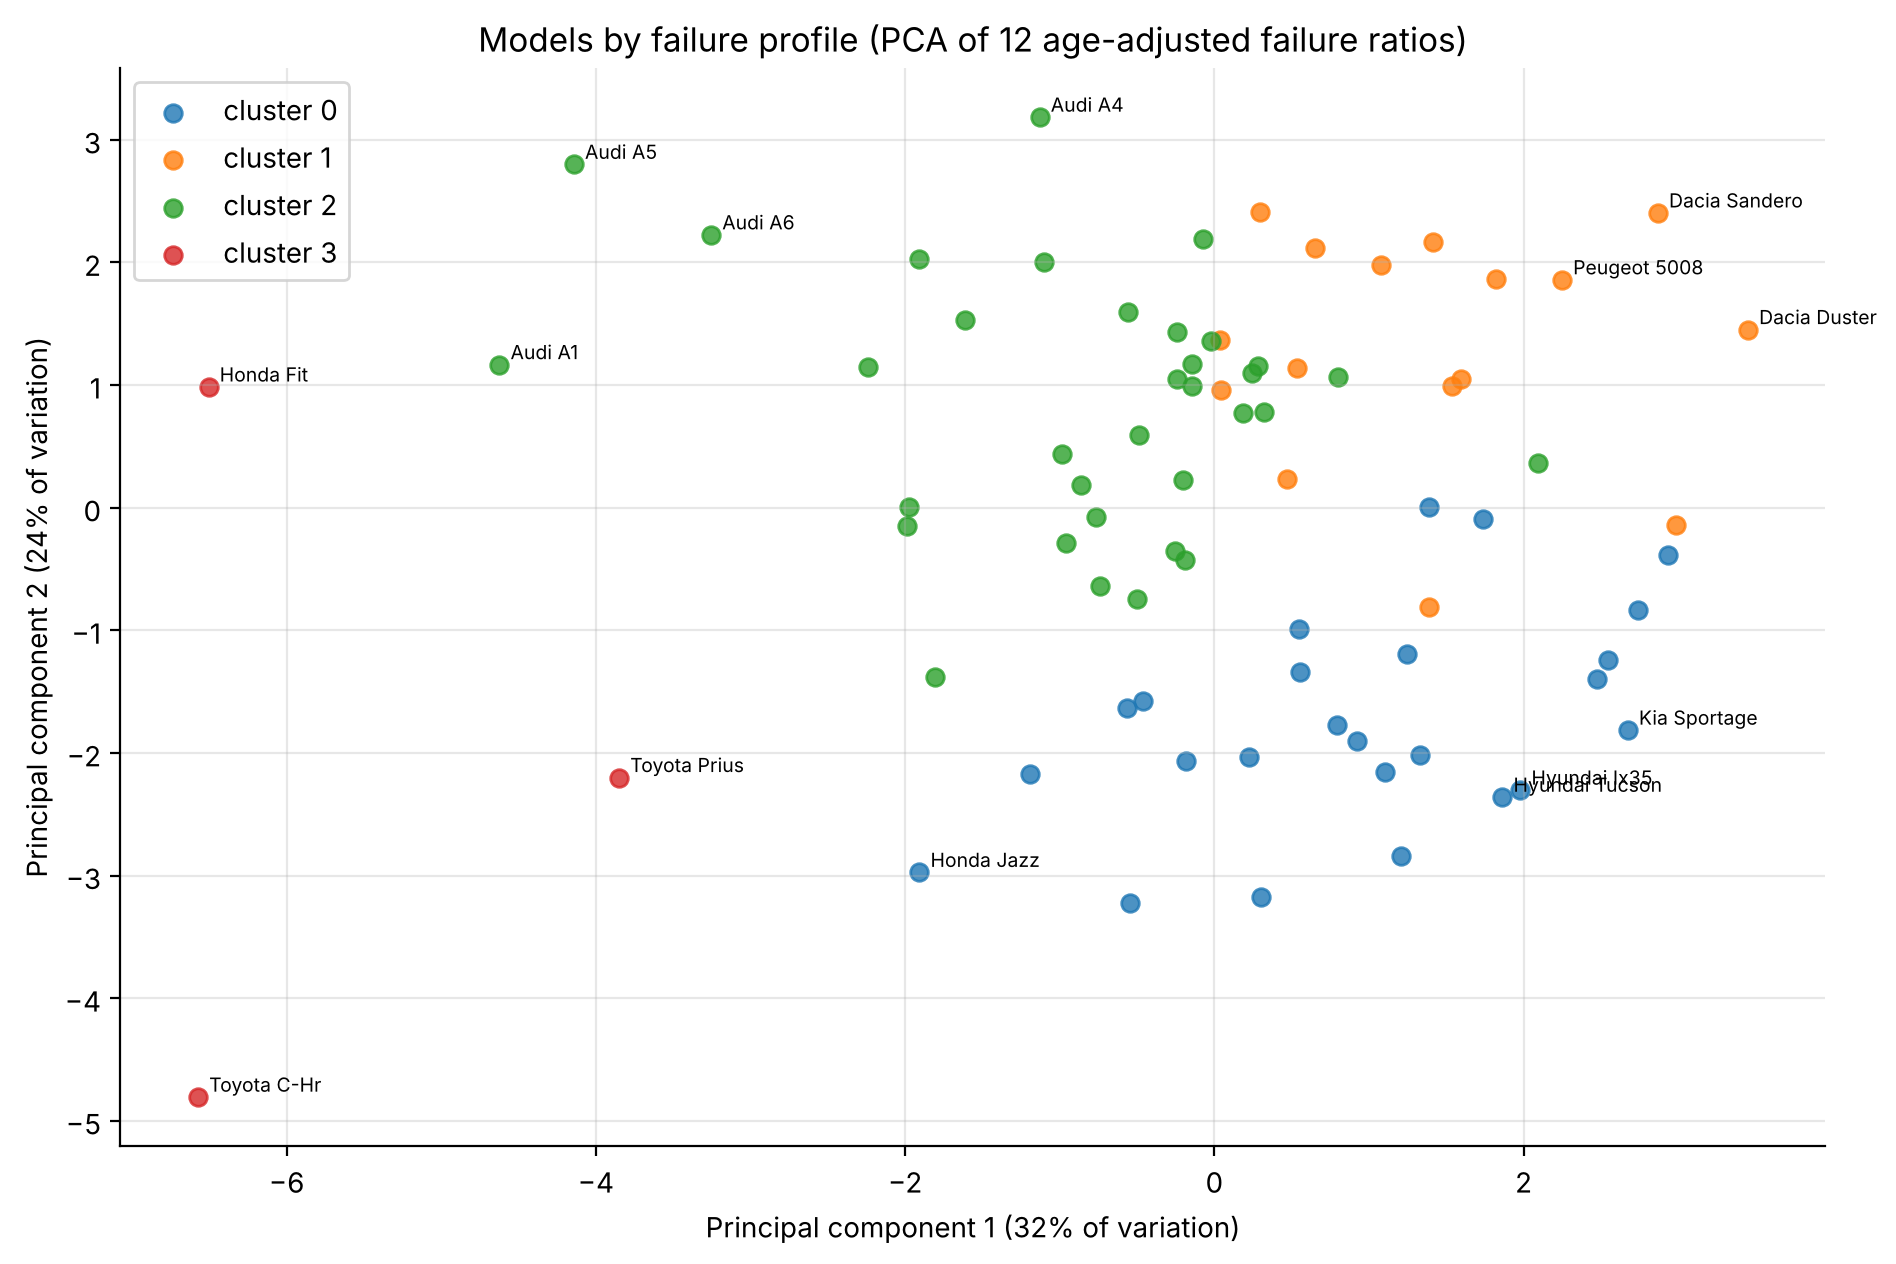

In [37]:
pca = PCA(n_components=2, random_state=RANDOM_SEED)
coords = pca.fit_transform(profile_matrix)

fig, ax = plt.subplots(figsize=(11, 7))
for c in range(K):
    mask = profiles["cluster"].to_numpy() == c
    ax.scatter(coords[mask, 0], coords[mask, 1], s=40, alpha=0.8, label=f"cluster {c}")
label_these = profiles.assign(dist=np.abs(coords).sum(axis=1)).sort_values("dist").index[-14:]
for name in label_these:
    i = profiles.index.get_loc(name)
    ax.annotate(name.replace(" | ", " ").title(), coords[i], fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
ax.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
ax.set_title("Models by failure profile (PCA of 12 age-adjusted failure ratios)")
ax.legend()
plt.show()

**Principal Component Analysis (PCA)** squeezes the 12 failure ratios into 2 dimensions for plotting, keeping as much of the variation as possible. The two components together keep a little over half of it, so the plot is a simplified view.

**Observation.** The clusters have recognisable characters (read the cluster table above, where green is better and red worse than an average car of the same age):

- One small cluster, containing the **Toyota Prius and C-HR** (models sold mainly as hybrids) and the **Honda Fit**, almost never fails on **emissions** or **engine, noise and exhaust**, and also does very well on steering and suspension.
- One cluster, containing many **Hyundai and Kia** models, fails more on **brakes** and **chassis and body**, and less on emissions and exhaust. Hyundai and Kia share a parent company and many parts, so it's reassuring that the clustering, which was never told the make, puts them together.
- One cluster fails more on almost **every** category, including many Renault, Dacia, Citroën, Peugeot and Vauxhall models.
- The largest cluster is average or slightly better than average on most items, and includes the common Ford, Audi and BMW models.

The failure profile says *what* to check on a used car of that model, which is more useful to a buyer than an overall fail rate.

## 11. Using the model

The project's original goal was a tool that gives the **probability that a car fails its next NCT**. The function below refits the chosen logistic regression on **all** years (2013–2025) and predicts for a future test year.

In [38]:
deployed_model = fit_logistic(model_data, **LOGISTIC_STEPS[BEST_LOGISTIC])


def fail_probability(make, model, year_of_birth, test_year=2026):
    """Estimated probability that a car of this make, model and year fails its NCT in test_year."""
    age = test_year - year_of_birth
    car = pd.DataFrame([{"make": make.upper(), "make_model": f"{make.upper()} | {model.upper()}",
                         "year_of_birth": year_of_birth, "age_capped": min(age, AGE_CAP),
                         "test_year": test_year}])
    if (car["make_model"][0] not in set(model_data["make_model"])):
        print(f"Note: {make} {model} isn't in the data, so only the make and age are used.")
    return float(predict_logistic(deployed_model, car)[0])


examples = [("FORD", "FOCUS", 2015), ("VOLKSWAGEN", "GOLF", 2015), ("TOYOTA", "COROLLA", 2015),
            ("NISSAN", "QASHQAI", 2015), ("SKODA", "OCTAVIA", 2015), ("RENAULT", "MEGANE", 2015),
            ("TOYOTA", "COROLLA", 2010), ("TOYOTA", "COROLLA", 2020)]
pd.DataFrame([{"car": f"{mk.title()} {md_.title()} ({y})", "age in 2026": 2026 - y,
               "fail probability (2026)": fail_probability(mk, md_, y)} for mk, md_, y in examples]
             ).style.format({"fail probability (2026)": "{:.0%}"}).hide(axis="index")

car,age in 2026,fail probability (2026)
Ford Focus (2015),11,52%
Volkswagen Golf (2015),11,44%
Toyota Corolla (2015),11,40%
Nissan Qashqai (2015),11,63%
Skoda Octavia (2015),11,49%
Renault Megane (2015),11,59%
Toyota Corolla (2010),16,57%
Toyota Corolla (2020),6,19%


**Observation.** For 11-year-old cars (built in 2015), the predicted chance of failing in 2026 ranges from well under half for the Toyota Corolla to well over half for some of the others. The age effect is just as clear for a single model: a 2010 Corolla is much more likely to fail than a 2020 one. These are averages for each type of car. An individual car's history and condition matter more than its badge.

## 12. Deployment

Deployment is the last phase of CRISP-DM. This is how the model could be put to use:

- **How it would be used.** A small web page or app where a used-car buyer enters a make, model and year and gets the predicted chance of failing the next NCT, together with the model's failure profile (Section 10), for example "check the brakes and the chassis".
- **Updating.** The RSA publishes a new file every year. Adding it to `data/` and re-running the notebook reloads all years, rebuilds the combined table and refits the models, because every step is a function and the loading code already handles all three file formats. The test year moves forward each time, so the model is always checked on the newest year before being used.
- **Monitoring.** Each new year is a free test set. If the group error rises noticeably above the 2025 level, the model should be reviewed. A year-wide shock like 2020 would show up straight away.
- **Communicating limits.** The tool should say clearly that predictions are averages for a type of car, that mileage and maintenance aren't taken into account, and that the RSA doesn't interpret the figures (Section 6).

## 13. Conclusion

**Question.** How likely is a car to fail its first NCT test, given its make, model and age? Which brands age best, and what do different models fail on?

**Answer.** Age is the main factor: fail rates rise from about one in five at four years old to about two in three by 15–20 years. Make and model matter too. After adjusting for age, Toyota and Honda cars fail least often and several French brands and Vauxhall most often. Logistic regression and a decision tree, trained on 2013–2024, both predicted the fail rates of every make/model/year group in 2025 more accurately than look-up baselines (an average error of about 4 percentage points, against 5), with almost identical accuracy to each other.

**What the work showed.**

1. **Data engineering mattered as much as modelling.** Thirteen files in three formats (PDF, CSV and Excel), with changing column names and changing privacy rules, had to become one consistent table. Checking the extraction found a tool that silently dropped rows, and an independent RSA file confirmed the totals.
2. **Fair comparisons need adjusting for age.** Raw fail rates make brands with older cars look worse. Age-adjusted fail ratios give a fairer ranking.
3. **When a car was built matters, not just its age.** The year of birth was the single most useful addition to the model: newer cars hold up better at the same age.
4. **Features mattered more than the choice of model.** Logistic regression and the decision tree ended up almost tied once each had good features. The tree is easier to explain, and confirms that age and the model's track record drive the predictions. Logistic regression gives slightly better probabilities.
5. **Clustering adds a different kind of insight.** Groups of models share failure patterns (hybrids with almost no emissions failures, Hyundai and Kia with more brake and chassis failures), which tells a buyer *what* to check, not just how likely a fail is.

**Limitations.**

- **No mileage, maintenance or service history.** A brand's fail rate partly reflects how its cars are used and looked after, not only how they are built.
- **Grouped data.** The data has totals per make, model and year, not individual cars, so the model can't use anything about a specific car.
- **Initial tests only, and small groups removed.** Rare cars can't be assessed, and retests aren't included.
- **Year-wide shifts** (such as 2020) can't be predicted from a car's make and model.

**Future work.** Mileage would be the most valuable addition, for example from used-car listings if they can be collected legally. Combining the profiles with the *cost* of typical repairs would turn "likely to fail on brakes" into an expected repair bill.

## References

- Road Safety Authority. *NCT statistics and annual reviews: Make and Model Data* (2013–2025) and *NCT pass/fail rates by test centre* (2025). https://www.rsa.ie/road-safety/statistics/nct-statistics-and-annual-reviews
- Road Safety Authority. *Make Model Year Failures at NCT* [datasets]. data.gov.ie. https://data.gov.ie/organization/road-safety-authority
- pypdf documentation. https://pypdf.readthedocs.io
- scikit-learn documentation: `LogisticRegression`, `DecisionTreeClassifier`, `KMeans`, `PCA`, `OneHotEncoder`, metrics. https://scikit-learn.org/stable/